# House price prediction with linear regression
**Nam · P4AI&DS · Working draft**

I compare ordinary least squares (OLS), Ridge, Lasso and ElasticNet on Housing (545 properties) and King County (21,613 transactions). A training-mean baseline gives a reference RMSE for each dataset. Prices stay in their original units.

Run the cells in order. To reproduce the team split, place the four index CSVs in `SPLIT_DIR` before B02. The final archive includes `nam_best_params.json` (settings by model and dataset), `nam_cv_results.csv` (validation scores) and `nam_test_results.csv` (holdout scores).


## B01 · Setup and data sources
Download the two CSVs and check their hashes, dimensions and column names. Each run writes its results to a separate folder.


In [1]:
# 1. IMPORTS

from pathlib import Path
import time
import json

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import Ridge, Lasso, ElasticNet

from sklearn.model_selection import KFold, GridSearchCV

from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)
import warnings, hashlib, platform, shutil
import sklearn, scipy, joblib
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import RandomizedSearchCV, learning_curve
from scipy.stats import loguniform
try:
    from IPython.display import display
except ImportError:
    display = print


In [2]:
# 2. Download Housing and King County data
from urllib.request import Request, urlopen
import io

PROJECT_DIR = (Path('/content') if Path('/content').exists() else Path.cwd()) / 'P4DS_Housing_Nam'
DATA_DIR = PROJECT_DIR / 'data' / 'raw'
RESULTS_DIR = PROJECT_DIR / 'results'
SPLIT_DIR = RESULTS_DIR / 'splits'
for folder in [DATA_DIR, RESULTS_DIR, SPLIT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_SOURCES = {
    'Housing.csv': {
        'url': 'https://raw.githubusercontent.com/reisanar/datasets/master/kaggle-housing.csv',
        'sha256': 'a8ef508351b4d6e87b23a831cf316a3d53c794ed9d969c7b697a865a60a3d65f',
        'shape': (545, 13),
        'columns': ['price','area','bedrooms','bathrooms','stories','mainroad','guestroom',
                    'basement','hotwaterheating','airconditioning','parking','prefarea','furnishingstatus'],
    },
    'kc_house_data.csv': {
        'url': 'https://raw.githubusercontent.com/jmatth11/King-County-House-Data-Set/master/kc_house_data.csv',
        'sha256': 'd0875baa0251b21d4bdc9d2ae940a4fe0bb6009824f23dd0e2a5b2bf04557b7e',
        'shape': (21613, 21),
        'columns': ['id','date','price','bedrooms','bathrooms','sqft_living','sqft_lot','floors',
                    'waterfront','view','condition','grade','sqft_above','sqft_basement',
                    'yr_built','yr_renovated','zipcode','lat','long','sqft_living15','sqft_lot15'],
    },
}
source_records = {}
for filename, spec in DATA_SOURCES.items():
    destination = DATA_DIR / filename
    if destination.exists():
        payload = destination.read_bytes()
        origin = 'existing_local_file'
    else:
        print('Downloading:', filename, flush=True)
        last_error = None
        for attempt in range(3):
            try:
                request = Request(spec['url'], headers={'User-Agent': 'Mozilla/5.0'})
                with urlopen(request, timeout=45) as response:
                    payload = response.read()
                break
            except Exception as exc:
                last_error = exc
                if attempt == 2:
                    raise RuntimeError(f'Could not download {filename} from {spec["url"]}') from last_error
                time.sleep(2)
        origin = 'downloaded_public_mirror'
    if origin == 'downloaded_public_mirror' and hashlib.sha256(payload).hexdigest() != spec['sha256']:
        raise ValueError(f'{filename}: file hash differs from the reference copy.')
    frame = pd.read_csv(io.BytesIO(payload))
    if frame.shape != spec['shape'] or list(frame.columns) != spec['columns']:
        raise ValueError(f'{filename}: unexpected columns or dimensions: {frame.shape}. Check the source file.')
    if not np.isfinite(frame['price']).all() or not (frame['price'] > 0).all():
        raise ValueError(f'{filename}: invalid target values.')
    if not destination.exists():
        temporary = destination.with_suffix('.download')
        temporary.write_bytes(payload)
        temporary.replace(destination)
    source_records[filename] = {
        'configured_mirror_url': spec['url'], 'origin': origin,
        'sha256': hashlib.sha256(payload).hexdigest(), 'shape': list(frame.shape),
        'original_team_file_match': 'not_verified',
    }
    print(filename, frame.shape, '— ready')
(DATA_DIR/'source_manifest.json').write_text(json.dumps(source_records,indent=2),encoding='utf-8')
print('Data:', DATA_DIR)


Downloading: Housing.csv
Housing.csv (545, 13) — ready
Downloading: kc_house_data.csv
kc_house_data.csv (21613, 21) — ready
Data: /content/P4DS_Housing_Nam/data/raw


In [3]:
# 3. Project paths
print('Project:', PROJECT_DIR)
print('Data:', DATA_DIR)
print('Results:', RESULTS_DIR)
print('Splits:', SPLIT_DIR)
print('Download the results before closing the runtime.')


Project: /content/P4DS_Housing_Nam
Data: /content/P4DS_Housing_Nam/data/raw
Results: /content/P4DS_Housing_Nam/results
Splits: /content/P4DS_Housing_Nam/results/splits
Download the results before closing the runtime.


In [4]:
from datetime import datetime, timezone
import uuid
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S') + '_' + uuid.uuid4().hex[:6]
RUN_DIR = RESULTS_DIR / ('nam_reviewed_v2_' + RUN_ID)
FIG_DIR = RUN_DIR / 'figures'
for p in [RUN_DIR, FIG_DIR, RUN_DIR/'checkpoints', RUN_DIR/'splits']:
    p.mkdir(parents=True, exist_ok=True)
versions = {'python':platform.python_version(), 'numpy':np.__version__,
            'pandas':pd.__version__, 'sklearn':sklearn.__version__, 'scipy':scipy.__version__}
(RUN_DIR/'environment.json').write_text(json.dumps(versions,indent=2))
print(versions)
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR/f'{name}.png', dpi=300, bbox_inches='tight')
    plt.savefig(FIG_DIR/f'{name}.pdf', bbox_inches='tight')
    plt.show()
    plt.close()
def checkpoint(name, **objects):
    # Only load checkpoints created by your own notebook.
    joblib.dump({'versions':versions, 'manifest':manifest,
                 'tuning_results':tuning_results, 'objects':objects},
                RUN_DIR/'checkpoints'/f'{name}.joblib')


{'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'scipy': '1.16.3'}


## B02 · Train and test partitions
Reuse the four team index files when available. If the directory is empty, recreate an 80/20 split with seed 42. Matching seeds alone cannot confirm that this reproduces the split used in the report.


In [5]:
# 4. LOAD DATASETS

HOUSING_PATH = DATA_DIR / "Housing.csv"
KC_PATH = DATA_DIR / "kc_house_data.csv"

if not HOUSING_PATH.exists():
    raise FileNotFoundError(f"Missing file: {HOUSING_PATH}")

if not KC_PATH.exists():
    raise FileNotFoundError(f"Missing file: {KC_PATH}")

housing = pd.read_csv(HOUSING_PATH)
king_county = pd.read_csv(KC_PATH)

print("Housing shape:", housing.shape)
print("King County shape:", king_county.shape)


Housing shape: (545, 13)
King County shape: (21613, 21)


In [6]:
# 5. DETERMINISTIC DATA PREPARATION

# Make copies to keep raw data unchanged
housing_clean = housing.copy()
kc_clean = king_county.copy()

# 5.1 Housing

housing_clean = (housing_clean .drop_duplicates() .reset_index(drop=True))

# 5.2 King County

kc_clean = (kc_clean .drop_duplicates() .reset_index(drop=True))

# Drop identifier column
if "id" in kc_clean.columns:
    kc_clean = kc_clean.drop(columns=["id"])

# Convert date into useful numerical features
if "date" in kc_clean.columns:

    kc_clean["date"] = pd.to_datetime(kc_clean["date"], format="%Y%m%dT%H%M%S", errors="coerce")

    kc_clean["sale_year"] = kc_clean["date"].dt.year
    kc_clean["sale_month"] = kc_clean["date"].dt.month

    kc_clean = kc_clean.drop(columns=["date"])

# Treat zipcode as categorical
if "zipcode" in kc_clean.columns:
    kc_clean["zipcode"] = kc_clean["zipcode"].astype("string")

print("Housing prepared:", housing_clean.shape)
print("King County prepared:", kc_clean.shape)


Housing prepared: (545, 13)
King County prepared: (21613, 21)


In [7]:
# 6. DEFINE FEATURES AND TARGET

TARGET = "price"

# Housing
X_housing = housing_clean.drop(columns=[TARGET])
y_housing = housing_clean[TARGET]

# King County
X_kc = kc_clean.drop(columns=[TARGET])
y_kc = kc_clean[TARGET]

print("Housing X:", X_housing.shape)
print("Housing y:", y_housing.shape)

print("\nKing County X:", X_kc.shape)
print("King County y:", y_kc.shape)


Housing X: (545, 12)
Housing y: (545,)

King County X: (21613, 20)
King County y: (21613,)


In [8]:
# Recreate the split only if the directory has no index files.
from sklearn.model_selection import train_test_split
split_names = [f'{ds}_{part}_indices.csv' for ds in ['housing','kingcounty'] for part in ['train','test']]
existence = [(SPLIT_DIR/name).exists() for name in split_names]
if any(existence) and not all(existence):
    raise RuntimeError('Incomplete split. Supply all four index files or start with an empty split directory.')
if not any(existence):
    for ds, total in [('housing',len(X_housing)),('kingcounty',len(X_kc))]:
        train_idx, test_idx = train_test_split(np.arange(total),test_size=0.2,random_state=42,shuffle=True)
        for part, values in [('train',train_idx),('test',test_idx)]:
            pd.DataFrame({'index':values}).to_csv(SPLIT_DIR/f'{ds}_{part}_indices.csv',index=False)
    split_provenance = {'mode':'reconstructed_seed42','original_team_membership_verified':False}
    (SPLIT_DIR/'split_provenance.json').write_text(json.dumps(split_provenance,indent=2))
else:
    provenance_path = SPLIT_DIR/'split_provenance.json'
    split_provenance = json.loads(provenance_path.read_text()) if provenance_path.exists() else {
        'mode':'existing_split_files','original_team_membership_verified':False}
print('Split provenance:', split_provenance)
print('Check split provenance before comparing results across teams.')
(RUN_DIR/'split_provenance.json').write_text(json.dumps(split_provenance,indent=2))
shutil.copy2(DATA_DIR/'source_manifest.json', RUN_DIR/'source_manifest.json')

# 7. LOAD FIXED TRAIN/TEST SPLITS

housing_train_idx = pd.read_csv(SPLIT_DIR / "housing_train_indices.csv")["index"].to_numpy()

housing_test_idx = pd.read_csv(SPLIT_DIR / "housing_test_indices.csv")["index"].to_numpy()

kc_train_idx = pd.read_csv(SPLIT_DIR / "kingcounty_train_indices.csv")["index"].to_numpy()

kc_test_idx = pd.read_csv(SPLIT_DIR / "kingcounty_test_indices.csv")["index"].to_numpy()

print("Housing train indices:", len(housing_train_idx))
print("Housing test indices :", len(housing_test_idx))

print("\nKing County train indices:", len(kc_train_idx))
print("King County test indices :", len(kc_test_idx))


Split provenance: {'mode': 'reconstructed_seed42', 'original_team_membership_verified': False}
Check split provenance before comparing results across teams.
Housing train indices: 436
Housing test indices : 109

King County train indices: 17290
King County test indices : 4323


In [9]:
def check_split(n, train, test):
    for a in [train,test]:
        assert np.issubdtype(a.dtype,np.integer), 'Indices must be integers'
        assert len(np.unique(a)) == len(a), 'Duplicate indices'
        assert len(a)>0 and a.min()>=0 and a.max()<n, 'Invalid indices'
    assert not np.intersect1d(train,test).size, 'Train/test overlap'
    assert np.array_equal(np.sort(np.r_[train,test]),np.arange(n)), 'Incomplete split'
check_split(len(X_housing),housing_train_idx,housing_test_idx)
check_split(len(X_kc),kc_train_idx,kc_test_idx)
for y in [y_housing,y_kc]:
    assert np.isfinite(y).all() and (y>0).all(), 'Missing/nonpositive target'
input_paths=[HOUSING_PATH,KC_PATH]+[SPLIT_DIR/f'{d}_{s}_indices.csv'
             for d in ['housing','kingcounty'] for s in ['train','test']]
manifest={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in input_paths}
(RUN_DIR/'input_hashes.json').write_text(json.dumps(manifest,indent=2))
for p in input_paths[2:]: shutil.copy2(p,RUN_DIR/'splits'/p.name)
print('PASS: valid disjoint exhaustive splits. Compare input_hashes.json across group members.')
# Keep ID only for audit, never a feature.
kc_meta=king_county.drop_duplicates().reset_index(drop=True)
id_overlap=set(kc_meta.loc[kc_train_idx,'id']) & set(kc_meta.loc[kc_test_idx,'id'])
print('King County shared property IDs across train/test:',len(id_overlap))
(RUN_DIR/'split_audit.json').write_text(json.dumps({'shared_property_ids':len(id_overlap),
    'split_interpretation':'row-level held-out sales; not guaranteed unseen properties'},indent=2))


PASS: valid disjoint exhaustive splits. Compare input_hashes.json across group members.
King County shared property IDs across train/test: 59


119

In [10]:
# 8. BUILD TRAIN/TEST SETS FROM FIXED INDICES

# Housing
X_train_h = X_housing.loc[housing_train_idx]
X_test_h = X_housing.loc[housing_test_idx]

y_train_h = y_housing.loc[housing_train_idx]
y_test_h = y_housing.loc[housing_test_idx]

# King County
X_train_kc = X_kc.loc[kc_train_idx]
X_test_kc = X_kc.loc[kc_test_idx]

y_train_kc = y_kc.loc[kc_train_idx]
y_test_kc = y_kc.loc[kc_test_idx]

print("Housing")
print("X_train:", X_train_h.shape)
print("X_test :", X_test_h.shape)
print("y_train:", y_train_h.shape)
print("y_test :", y_test_h.shape)

print("\nKing County")
print("X_train:", X_train_kc.shape)
print("X_test :", X_test_kc.shape)
print("y_train:", y_train_kc.shape)
print("y_test :", y_test_kc.shape)


Housing
X_train: (436, 12)
X_test : (109, 12)
y_train: (436,)
y_test : (109,)

King County
X_train: (17290, 20)
X_test : (4323, 20)
y_train: (17290,)
y_test : (4323,)


## B03 · Training data summary
Inspect missing values, duplicate rows and feature distributions. The IQR counts describe the tails of each distribution. High-priced properties stay in the sample.


Housing raw duplicates 0 train price IQR flags 12


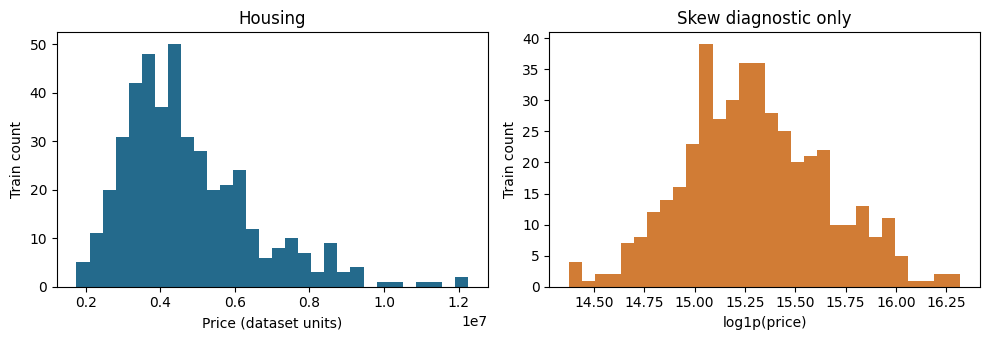

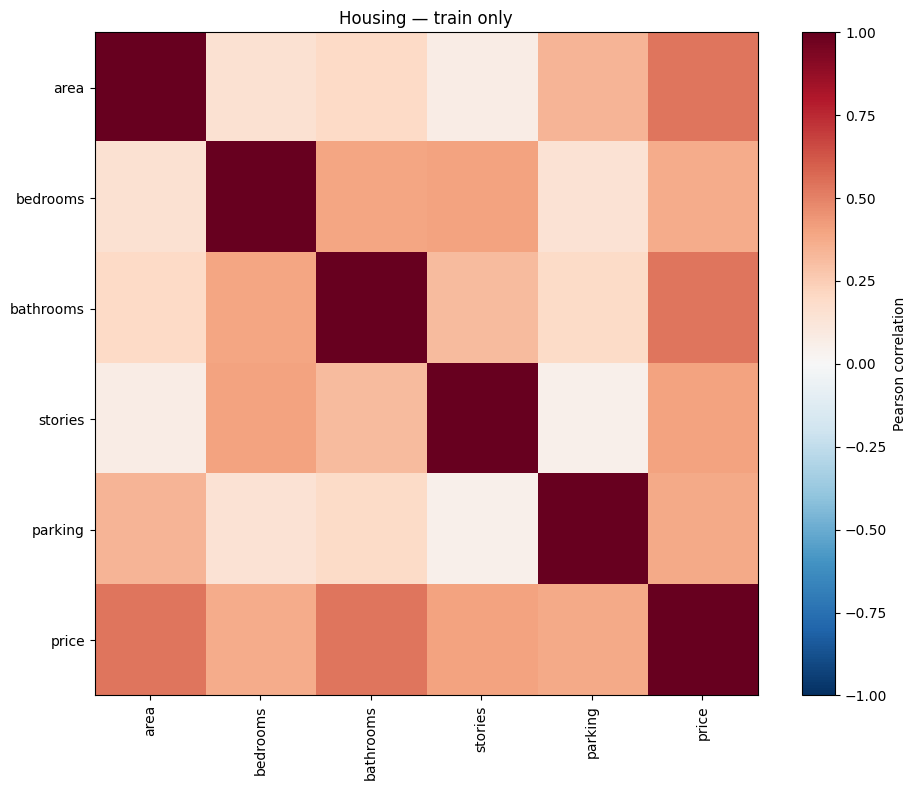

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus


KingCounty raw duplicates 0 train price IQR flags 912


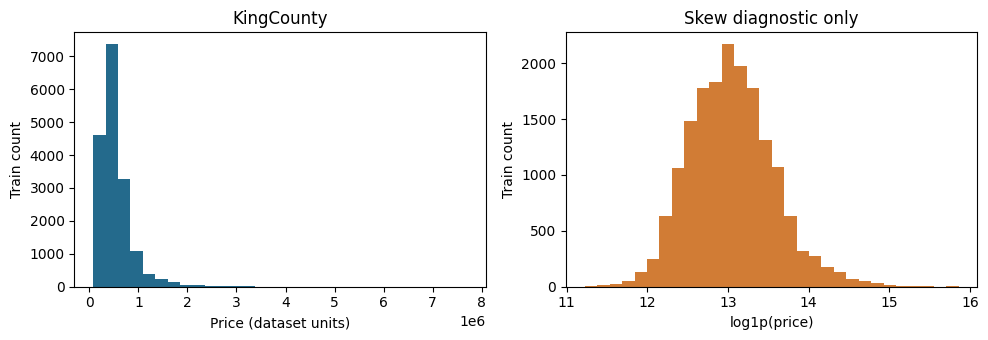

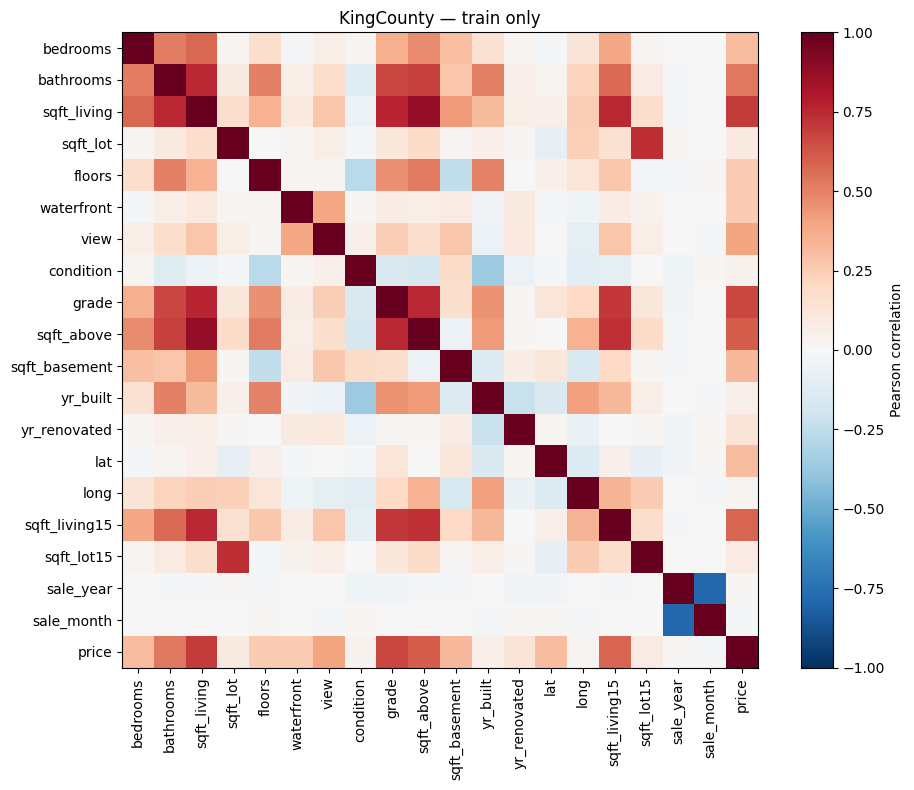

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month
15870,33,1.75,1620,6000,1.0,0,0,5,7,1040,580,1947,0,98103,47.6878,-122.331,1330,4700,2014,6


In [11]:
for name, X, y, raw in [('Housing',X_train_h,y_train_h,housing),
                          ('KingCounty',X_train_kc,y_train_kc,king_county)]:
    X.describe(include='all').to_csv(RUN_DIR/f'{name}_train_describe.csv')
    X.isna().sum().rename('missing_count').to_csv(RUN_DIR/f'{name}_missing.csv')
    q1,q3=y.quantile([.25,.75]); upper=q3+1.5*(q3-q1)
    print(name,'raw duplicates',raw.duplicated().sum(),'train price IQR flags',int((y>upper).sum()))
    fig,ax=plt.subplots(1,2,figsize=(10,3.5))
    ax[0].hist(y,bins=30,color='#246a8c');ax[0].set(xlabel='Price (dataset units)',ylabel='Train count',title=name)
    ax[1].hist(np.log1p(y),bins=30,color='#d17c35');ax[1].set(xlabel='log1p(price)',ylabel='Train count',title='Skew diagnostic only')
    savefig(f'{name}_price_distribution')
    corr=X.select_dtypes(include='number').assign(price=y).corr()
    fig,ax=plt.subplots(figsize=(10,8));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
    ax.set_xticks(range(len(corr)),corr.columns,rotation=90);ax.set_yticks(range(len(corr)),corr.columns)
    fig.colorbar(im,ax=ax,label='Pearson correlation');ax.set_title(name+' — train only')
    savefig(f'{name}_correlation')
    if 'bedrooms' in X: display(X.loc[X['bedrooms']>10].head(10))


## B04 · Preprocessing and cross-validation
Fit the preprocessing pipeline inside each training fold. Use median imputation and standardization for numeric features, and mode imputation and one-hot encoding for categorical features. All models use five folds with seed 36.


In [12]:
# 9. FEATURE TYPES AND PREPROCESSING

# 9.1 Identify numerical and categorical features

housing_numeric = X_train_h.select_dtypes(include=["number", "bool"]).columns.tolist()

housing_categorical = X_train_h.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

kc_numeric = X_train_kc.select_dtypes(include=["number", "bool"]).columns.tolist()

kc_categorical = X_train_kc.select_dtypes(include=["object", "category", "string"]).columns.tolist()

print("HOUSING")
print("Numerical:", housing_numeric)
print("Categorical:", housing_categorical)

print("\nKING COUNTY")
print("Numerical:", kc_numeric)
print("Categorical:", kc_categorical)


HOUSING
Numerical: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']

KING COUNTY
Numerical: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month']
Categorical: ['zipcode']


In [13]:
# 9.2 BUILD PREPROCESSING PIPELINES

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

housing_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, housing_numeric),
    ("cat", categorical_pipeline, housing_categorical)
])

kc_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, kc_numeric),
    ("cat", categorical_pipeline, kc_categorical)
])

print("Housing preprocessor ready.")
print("King County preprocessor ready.")


Housing preprocessor ready.
King County preprocessor ready.


In [14]:
# 10. CROSS-VALIDATION CONFIGURATION

CV_FOLDS = 5
CV_SEED = 36

cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=CV_SEED)

SCORING = "neg_root_mean_squared_error"

# Central container for later CV summary/export
tuning_results = {}

print("CV folds :", CV_FOLDS)
print("CV seed  :", CV_SEED)
print("Scoring  :", SCORING)


CV folds : 5
CV seed  : 36
Scoring  : neg_root_mean_squared_error


## B05 · Ridge penalty search
Start with a coarse alpha grid, then search a narrower interval around the lowest cross-validation RMSE. Check whether the selected value sits at the edge of the grid.


In [15]:
# 11.1 RIDGE COARSE-TO-FINE TUNING FUNCTION

def tune_ridge_two_stage(dataset_name, X_train, y_train, preprocessor):
    """
    Tune Ridge alpha using:
    1. broad logarithmic coarse GridSearchCV
    2. local fine GridSearchCV around the coarse optimum

    No held-out test data are used.
    """

    ridge_pipeline = Pipeline([("preprocess", clone(preprocessor)), ("model", Ridge())])

    # --------------------------------------------------------
    # Stage 1: Coarse search
    # --------------------------------------------------------

    coarse_alphas = np.logspace(-4, 4, 41)

    coarse_grid = { "model__alpha": coarse_alphas }

    start = time.perf_counter()

    coarse_search = GridSearchCV(
        estimator=ridge_pipeline,
        param_grid=coarse_grid,
        scoring=SCORING,
        cv=cv,
        n_jobs=-1,
        refit=False,
        return_train_score=False
    )

    coarse_search.fit(X_train, y_train)

    coarse_best_alpha = float(coarse_search.best_params_["model__alpha"])

    coarse_best_rmse = float(-coarse_search.best_score_)

    print(f"\n{dataset_name} — Ridge coarse search")
    print("Best coarse alpha   :", coarse_best_alpha)
    print("Best coarse CV RMSE :", f"{coarse_best_rmse:,.3f}")

    # Boundary check
    if (
        np.isclose(coarse_best_alpha, coarse_alphas.min())
        or
        np.isclose(coarse_best_alpha, coarse_alphas.max())
    ):
        raise ValueError(
            f"{dataset_name}: coarse Ridge optimum is at "
            "the search boundary. Expand the coarse alpha range."
        )

    # --------------------------------------------------------
    # Stage 2: Fine search
    # --------------------------------------------------------

    fine_alphas = np.geomspace(coarse_best_alpha / 2, coarse_best_alpha * 2, 41)

    fine_grid = { "model__alpha": fine_alphas }

    fine_search = GridSearchCV(
        estimator=ridge_pipeline,
        param_grid=fine_grid,
        scoring=SCORING,
        cv=cv,
        n_jobs=-1,
        refit=False,
        return_train_score=False
    )

    fine_search.fit(X_train, y_train)

    tuning_time = (time.perf_counter() - start)

    best_alpha = float(fine_search.best_params_["model__alpha"])

    best_cv_rmse = float(-fine_search.best_score_)

    best_cv_std = float(fine_search.cv_results_["std_test_score"][fine_search.best_index_])

    # --------------------------------------------------------
    # Store standardized result
    # --------------------------------------------------------

    tuning_results[
        (dataset_name, "Ridge")
    ] = {
        "dataset": dataset_name,
        "model": "Ridge",
        "search_method": (
            "coarse-to-fine GridSearchCV"
        ),
        "best_alpha": best_alpha,
        "best_l1_ratio": np.nan,
        "mean_cv_rmse": best_cv_rmse,
        "std_cv_rmse": best_cv_std,
        "cv_folds": CV_FOLDS,
        "cv_seed": CV_SEED,
        "tuning_time_sec": tuning_time,
        "fold_safe_preprocessing": True,
        "status": "final"
    }

    print(f"\n{dataset_name} — Ridge FINAL")
    print("Best alpha        :", best_alpha)
    print("Mean CV RMSE      :", f"{best_cv_rmse:,.3f}")
    print("CV RMSE std       :", f"{best_cv_std:,.3f}")
    print("Tuning time       :", f"{tuning_time:.3f} seconds")

    return {
        "coarse_search": coarse_search,
        "fine_search": fine_search,
        "coarse_alphas": coarse_alphas,
        "fine_alphas": fine_alphas
    }


In [16]:
# 11.2 RIDGE - HOUSING

ridge_housing_result = tune_ridge_two_stage(
    dataset_name="Housing",
    X_train=X_train_h,
    y_train=y_train_h,
    preprocessor=housing_preprocessor
)



Housing — Ridge coarse search
Best coarse alpha   : 15.848931924611142
Best coarse CV RMSE : 1,030,945.783

Housing — Ridge FINAL
Best alpha        : 18.205642030260815
Mean CV RMSE      : 1,030,918.888
CV RMSE std       : 71,435.483
Tuning time       : 11.573 seconds


In [17]:
# 11.3 RIDGE - KING COUNTY

ridge_kc_result = tune_ridge_two_stage(
    dataset_name="King County",
    X_train=X_train_kc,
    y_train=y_train_kc,
    preprocessor=kc_preprocessor
)



King County — Ridge coarse search
Best coarse alpha   : 0.3981071705534973
Best coarse CV RMSE : 159,550.580

King County — Ridge FINAL
Best alpha        : 0.45730505192732646
Mean CV RMSE      : 159,548.811
CV RMSE std       : 5,237.221
Tuning time       : 63.997 seconds


In [18]:
checkpoint('ridge',housing=ridge_housing_result,kingcounty=ridge_kc_result)


## B06 · Lasso penalty path
Select the converged alpha with the lowest mean validation RMSE. If a cold-start fold fit or the full training fit fails to converge, check the one-standard-error candidate. Report fold variability using the sample standard deviation.


In [19]:
# 12.2 FOLD-SAFE WARM-START LASSO PATH

def evaluate_lasso_path_cv(X, y, preprocessor, alphas, max_iter=20000, tol=1e-4):
    """
    Evaluate an ordered Lasso alpha path using 5-fold CV.

    Important:
    - preprocessing is fitted separately inside each CV fold;
    - alpha values are evaluated from large to small;
    - warm_start reuses the previous coefficient solution;
    - convergence is monitored explicitly.
    """

    alphas = np.array(sorted(np.asarray(alphas, dtype=float), reverse=True))

    records = []

    start = time.perf_counter()

    for fold_id, (fold_train_idx, fold_val_idx) in enumerate(cv.split(X), start=1):

        # ----------------------------------------------------
        # Current CV split
        # ----------------------------------------------------

        X_fold_train = X.iloc[fold_train_idx]
        X_fold_val = X.iloc[fold_val_idx]

        y_fold_train = y.iloc[fold_train_idx]
        y_fold_val = y.iloc[fold_val_idx]

        # ----------------------------------------------------
        # Fold-safe preprocessing
        # ----------------------------------------------------

        fold_preprocessor = clone(preprocessor)

        X_fold_train_t = (fold_preprocessor .fit_transform(X_fold_train, y_fold_train))

        X_fold_val_t = (fold_preprocessor .transform(X_fold_val))

        # ----------------------------------------------------
        # Warm-start Lasso path
        # ----------------------------------------------------

        fold_lasso = Lasso(
            alpha=float(alphas[0]),
            max_iter=max_iter,
            tol=tol,
            selection="cyclic",
            warm_start=True
        )

        for alpha in alphas:

            fold_lasso.set_params(alpha=float(alpha))

            with warnings.catch_warnings(record=True) as caught_warnings:

                warnings.simplefilter("always", ConvergenceWarning)

                fold_lasso.fit(X_fold_train_t, y_fold_train)

            convergence_warning = any(
                issubclass(
                    warning.category,
                    ConvergenceWarning
                )
                for warning
                in caught_warnings
            )

            y_val_pred = (fold_lasso.predict(X_fold_val_t))

            fold_rmse = np.sqrt(mean_squared_error(y_fold_val, y_val_pred))

            converged = (not convergence_warning and fold_lasso.n_iter_ < max_iter)

            records.append({
                "fold": fold_id,
                "alpha": float(alpha),
                "rmse": float(fold_rmse),
                "dual_gap": float(fold_lasso.dual_gap_),
                "convergence_warning": bool(convergence_warning),
                "n_iter": int(
                    fold_lasso.n_iter_
                ),
                "converged": bool(
                    converged
                )
            })

        print(f"Fold {fold_id}/{CV_FOLDS} completed.")

    tuning_time = (time.perf_counter() - start)

    records_df = pd.DataFrame(records)

    summary_df = (
        records_df
        .groupby(
            "alpha",
            as_index=False
        )
        .agg(
            mean_cv_rmse=(
                "rmse",
                "mean"
            ),
            std_cv_rmse=(
                "rmse",
                "std"
            ),
            max_n_iter=(
                "n_iter",
                "max"
            ),
            all_folds_converged=(
                "converged",
                lambda x: bool(
                    x.all()
                )
            )
        )
    )

    summary_df["se_cv_rmse"] = (summary_df["std_cv_rmse"] / np.sqrt(CV_FOLDS))

    return (records_df, summary_df, tuning_time)


In [20]:
# 12.3 ONE-STANDARD-ERROR SELECTOR

def select_lasso_one_se(summary_df):
    """
    Select Lasso alpha using the one-standard-error rule.

    Only alpha values that converged in all CV folds
    are eligible for final selection.
    """

    converged_summary = (summary_df[summary_df["all_folds_converged"]] .copy())

    if converged_summary.empty:
        raise RuntimeError("No Lasso alpha converged " "across all CV folds.")

    # --------------------------------------------------------
    # RMSE-minimizing alpha
    # --------------------------------------------------------

    min_idx = (converged_summary["mean_cv_rmse"] .idxmin())

    min_row = (converged_summary .loc[min_idx])

    alpha_min = float(min_row["alpha"])

    min_cv_rmse = float(min_row["mean_cv_rmse"])

    min_se = float(min_row["se_cv_rmse"])

    # --------------------------------------------------------
    # 1-SE threshold
    # --------------------------------------------------------

    one_se_threshold = (min_cv_rmse + min_se)

    eligible = (converged_summary[converged_summary["mean_cv_rmse"] <= one_se_threshold] .copy())

    # Largest alpha = strongest regularization
    selected_row = (eligible .sort_values("alpha", ascending=False) .iloc[0])

    selected_alpha = float(selected_row["alpha"])

    selected_cv_rmse = float(selected_row["mean_cv_rmse"])

    selected_std = float(selected_row["std_cv_rmse"])

    return {
        "alpha_min": alpha_min,
        "min_cv_rmse": min_cv_rmse,
        "min_se": min_se,
        "one_se_threshold":
            one_se_threshold,
        "selected_alpha":
            selected_alpha,
        "selected_cv_rmse":
            selected_cv_rmse,
        "selected_std":
            selected_std
    }


In [21]:
# 12.4 LASSO TUNING WRAPPER

def tune_lasso_one_se(dataset_name, X_train, y_train, preprocessor, alphas):
    """
    Final Lasso tuning procedure.

    PRIMARY model-selection rule:
        Select alpha with the minimum mean 5-fold CV RMSE.

    SECONDARY analysis:
        Also compute the one-standard-error (1-SE) alpha
        as a more regularized / parsimonious alternative.

    Uses:
    - fold-safe preprocessing
    - warm-start alpha path
    - 5-fold cross-validation
    - RMSE-min selection for final model comparison
    - 1-SE rule for secondary sparsity analysis

    The held-out test set is never used.
    """

    # ========================================================
    # 1. EVALUATE LASSO PATH
    # ========================================================

    (
        records_df,
        summary_df,
        tuning_time
    ) = evaluate_lasso_path_cv(
        X=X_train,
        y=y_train,
        preprocessor=preprocessor,
        alphas=alphas,
        max_iter=20000,
        tol=1e-4
    )

    # ========================================================
    # 2. APPLY ONE-STANDARD-ERROR ANALYSIS
    # ========================================================

    selection = select_lasso_one_se(summary_df)

    # --------------------------------------------------------
    # PRIMARY configuration:
    # alpha that minimizes CV RMSE
    # --------------------------------------------------------

    best_alpha = float(selection["alpha_min"])

    best_cv_rmse = float(selection["min_cv_rmse"])

    # Retrieve CV standard deviation at RMSE-min alpha
    best_alpha_mask = np.isclose(summary_df["alpha"], best_alpha)

    best_cv_std = float(summary_df.loc[best_alpha_mask, "std_cv_rmse"].iloc[0])

    # --------------------------------------------------------
    # SECONDARY configuration:
    # one-standard-error alpha
    # --------------------------------------------------------

    alpha_1se = float(selection["selected_alpha"])

    cv_rmse_1se = float(selection["selected_cv_rmse"])

    one_se_threshold = float(selection["one_se_threshold"])

    # ========================================================
    # 3. BOUNDARY INFORMATION
    # ========================================================

    alpha_min_candidate = float(np.min(alphas))

    alpha_max_candidate = float(np.max(alphas))

    rmse_min_at_lower_boundary = (np.isclose(best_alpha, alpha_min_candidate))

    rmse_min_at_upper_boundary = (np.isclose(best_alpha, alpha_max_candidate))

    alpha_1se_at_upper_boundary = (np.isclose(alpha_1se, alpha_max_candidate))

    # ========================================================
    # 4. STORE STANDARDIZED RESULT
    # ========================================================

    tuning_results[
        (dataset_name, "Lasso")
    ] = {
        "dataset":
            dataset_name,

        "model":
            "Lasso",

        "search_method":
            "fold-safe warm-start path CV + 1SE analysis",

        # ----------------------------------------------------
        # PRIMARY result used for model comparison
        # ----------------------------------------------------

        "best_alpha":
            best_alpha,

        "best_l1_ratio":
            np.nan,

        "mean_cv_rmse":
            best_cv_rmse,

        "std_cv_rmse":
            best_cv_std,

        # ----------------------------------------------------
        # SECONDARY parsimonious result
        # ----------------------------------------------------

        "alpha_1se":
            alpha_1se,

        "cv_rmse_1se":
            cv_rmse_1se,

        "one_se_threshold":
            one_se_threshold,

        # ----------------------------------------------------
        # CV protocol
        # ----------------------------------------------------

        "cv_folds":
            CV_FOLDS,

        "cv_seed":
            CV_SEED,

        "tuning_time_sec":
            tuning_time,

        "fold_safe_preprocessing":
            True,

        # ----------------------------------------------------
        # Diagnostic information
        # ----------------------------------------------------

        "rmse_min_at_lower_boundary":
            rmse_min_at_lower_boundary,

        "rmse_min_at_upper_boundary":
            rmse_min_at_upper_boundary,

        "alpha_1se_at_upper_boundary":
            alpha_1se_at_upper_boundary,

        "status":
            "path_candidate_pending_audit"
    }

    # ========================================================
    # 5. PRINT FINAL RESULT
    # ========================================================

    print(f"\n{dataset_name} — Lasso PATH CANDIDATES")

    print("\nPRIMARY MODEL-SELECTION RESULT")

    print("RMSE-min alpha       :", best_alpha)

    print("Minimum CV RMSE      :", f"{best_cv_rmse:,.3f}")

    print("CV RMSE std          :", f"{best_cv_std:,.3f}")

    print("\nSECONDARY 1-SE RESULT")

    print("1-SE alpha           :", alpha_1se)

    print("1-SE CV RMSE         :", f"{cv_rmse_1se:,.3f}")

    print("1-SE threshold       :", f"{one_se_threshold:,.3f}")

    print("\nDIAGNOSTICS")

    print("RMSE-min lower bound :", rmse_min_at_lower_boundary)

    print("RMSE-min upper bound :", rmse_min_at_upper_boundary)

    print("1-SE upper bound     :", alpha_1se_at_upper_boundary)

    print("Tuning time          :", f"{tuning_time:.3f} seconds")

    print("Status               : pending cold-start/full-training audit")

    # ========================================================
    # 6. RETURN COMPLETE RESULTS
    # ========================================================

    return {
        "records":
            records_df,

        "summary":
            summary_df,

        "selection":
            selection,

        "best_alpha":
            best_alpha,

        "best_cv_rmse":
            best_cv_rmse,

        "alpha_1se":
            alpha_1se,

        "cv_rmse_1se":
            cv_rmse_1se
    }


In [22]:
# 12.5 FINAL LASSO ALPHA PATHS

housing_lasso_alphas = np.geomspace(1e5, 1e2, 13)

kc_lasso_alphas = np.geomspace(1e4, 1e-1, 11)

print("Housing alpha candidates:")
print(housing_lasso_alphas)

print("\nKing County alpha candidates:")
print(kc_lasso_alphas)


Housing alpha candidates:
[100000.          56234.13251903  31622.77660168  17782.79410039
  10000.           5623.4132519    3162.27766017   1778.27941004
   1000.            562.34132519    316.22776602    177.827941
    100.        ]

King County alpha candidates:
[1.00000000e+04 3.16227766e+03 1.00000000e+03 3.16227766e+02
 1.00000000e+02 3.16227766e+01 1.00000000e+01 3.16227766e+00
 1.00000000e+00 3.16227766e-01 1.00000000e-01]


In [23]:
# 12.6 LASSO - HOUSING

lasso_housing_result = (
    tune_lasso_one_se(
        dataset_name="Housing",
        X_train=X_train_h,
        y_train=y_train_h,
        preprocessor=
            housing_preprocessor,
        alphas=
            housing_lasso_alphas
    )
)


Fold 1/5 completed.
Fold 2/5 completed.
Fold 3/5 completed.
Fold 4/5 completed.
Fold 5/5 completed.

Housing — Lasso PATH CANDIDATES

PRIMARY MODEL-SELECTION RESULT
RMSE-min alpha       : 3162.2776601683795
Minimum CV RMSE      : 1,033,564.138
CV RMSE std          : 78,116.120

SECONDARY 1-SE RESULT
1-SE alpha           : 56234.13251903491
1-SE CV RMSE         : 1,064,839.941
1-SE threshold       : 1,068,498.729

DIAGNOSTICS
RMSE-min lower bound : False
RMSE-min upper bound : False
1-SE upper bound     : False
Tuning time          : 0.242 seconds
Status               : pending cold-start/full-training audit


In [24]:
# 12.7 LASSO - KING COUNTY

lasso_kc_result = (
    tune_lasso_one_se(
        dataset_name="King County",
        X_train=X_train_kc,
        y_train=y_train_kc,
        preprocessor=
            kc_preprocessor,
        alphas=
            kc_lasso_alphas
    )
)


Fold 1/5 completed.
Fold 2/5 completed.
Fold 3/5 completed.
Fold 4/5 completed.
Fold 5/5 completed.

King County — Lasso PATH CANDIDATES

PRIMARY MODEL-SELECTION RESULT
RMSE-min alpha       : 0.1
Minimum CV RMSE      : 159,554.902
CV RMSE std          : 5,908.183

SECONDARY 1-SE RESULT
1-SE alpha           : 316.22776601683796
1-SE CV RMSE         : 161,823.857
1-SE threshold       : 162,197.122

DIAGNOSTICS
RMSE-min lower bound : True
RMSE-min upper bound : False
1-SE upper bound     : False
Tuning time          : 64.705 seconds
Status               : pending cold-start/full-training audit


In [25]:
checkpoint('lasso',housing=lasso_housing_result,kingcounty=lasso_kc_result)


## B07 · ElasticNet on Housing
Tune alpha and the L1 ratio on a coarse grid, then refine the search locally. B09 checks convergence of the selected settings in each fold.


In [26]:
# 13.1 HOUSING ELASTICNET PIPELINE + SEARCH SPACE

housing_en_pipeline = Pipeline([
    (
        "preprocess",
        clone(housing_preprocessor)
    ),
    (
        "model",
        ElasticNet(
            max_iter=50000,
            tol=1e-4,
            selection="cyclic"
        )
    )
])

# Alpha: logarithmic search

housing_en_alphas = np.logspace(-4, 3, 29)

# l1_ratio:
# more resolution near the Lasso-like region

housing_en_l1_ratios = [0.10, 0.30, 0.50, 0.70, 0.85, 0.90, 0.95, 0.98, 0.99]

housing_en_param_grid = {
    "model__alpha":
        housing_en_alphas,

    "model__l1_ratio":
        housing_en_l1_ratios
}

# Search-space diagnostics

n_alpha = len(housing_en_alphas)

n_ratio = len(housing_en_l1_ratios)

n_candidates = (n_alpha * n_ratio)

n_cv_fits = (n_candidates * CV_FOLDS)

print("Housing ElasticNet search-space check")

print("\nAlpha candidates :", n_alpha)

print("Alpha minimum    :", housing_en_alphas.min())

print("Alpha maximum    :", housing_en_alphas.max())

print("\nl1_ratio candidates:", n_ratio)

print(housing_en_l1_ratios)

print("\nGrid candidates  :", n_candidates)

print("Total CV fits    :", n_cv_fits)


Housing ElasticNet search-space check

Alpha candidates : 29
Alpha minimum    : 0.0001
Alpha maximum    : 1000.0

l1_ratio candidates: 9
[0.1, 0.3, 0.5, 0.7, 0.85, 0.9, 0.95, 0.98, 0.99]

Grid candidates  : 261
Total CV fits    : 1305


In [27]:
# 13.2 HOUSING ELASTICNET GRID SEARCH

housing_en_search = GridSearchCV(
    estimator=housing_en_pipeline,
    param_grid=housing_en_param_grid,
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
    refit=False,
    return_train_score=False,
    error_score="raise"
)

start = time.perf_counter()

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always", ConvergenceWarning)

    housing_en_search.fit(X_train_h, y_train_h)

housing_en_tuning_time = (time.perf_counter() - start)

# Best CV result

housing_en_best_alpha = float(housing_en_search.best_params_["model__alpha"])

housing_en_best_l1_ratio = float(housing_en_search.best_params_["model__l1_ratio"])

housing_en_best_rmse = float(-housing_en_search.best_score_)

housing_en_best_std = float(
    housing_en_search.cv_results_[
        "std_test_score"
    ][housing_en_search.best_index_]
)

# Count convergence warnings

n_convergence_warnings = sum(issubclass(w.category, ConvergenceWarning) for w in caught_warnings)

print("Housing — ElasticNet GridSearchCV")

print("\nBest alpha          :", housing_en_best_alpha)

print("Best l1_ratio       :", housing_en_best_l1_ratio)

print("Mean CV RMSE        :", f"{housing_en_best_rmse:,.3f}")

print("CV RMSE std         :", f"{housing_en_best_std:,.3f}")

print("Tuning time         :", f"{housing_en_tuning_time:.3f} sec")

print("Convergence warnings captured in parent process:", n_convergence_warnings)


Housing — ElasticNet GridSearchCV

Best alpha          : 0.05623413251903491
Best l1_ratio       : 0.1
Mean CV RMSE        : 1,030,916.117
CV RMSE std         : 71,386.989
Tuning time         : 87.327 sec
Convergence warnings captured in parent process: 0


In [28]:
# 13.2B HOUSING SEARCH BOUNDARY CHECK

alpha_at_lower_boundary = np.isclose(housing_en_best_alpha, housing_en_alphas.min())

alpha_at_upper_boundary = np.isclose(housing_en_best_alpha, housing_en_alphas.max())

ratio_at_lower_boundary = np.isclose(housing_en_best_l1_ratio, min(housing_en_l1_ratios))

ratio_at_upper_boundary = np.isclose(housing_en_best_l1_ratio, max(housing_en_l1_ratios))

print("Alpha lower boundary :", alpha_at_lower_boundary)

print("Alpha upper boundary :", alpha_at_upper_boundary)

print("Ratio lower boundary :", ratio_at_lower_boundary)

print("Ratio upper boundary :", ratio_at_upper_boundary)

if (
    alpha_at_lower_boundary
    or alpha_at_upper_boundary
    or ratio_at_lower_boundary
    or ratio_at_upper_boundary
):
    print("\nSEARCH STATUS: REVIEW NEEDED")
else:
    print("\nSEARCH STATUS: PASS")


Alpha lower boundary : False
Alpha upper boundary : False
Ratio lower boundary : True
Ratio upper boundary : False

SEARCH STATUS: REVIEW NEEDED


In [29]:
# 13.2C HOUSING ELASTICNET LOCAL REFINEMENT

housing_en_refine_alphas = np.geomspace(housing_en_best_alpha / 4, housing_en_best_alpha * 4, 7)

housing_en_refine_l1_ratios = [0.02, 0.05, 0.10, 0.15, 0.20, 0.30]

housing_en_refine_grid = {
    "model__alpha":
        housing_en_refine_alphas,

    "model__l1_ratio":
        housing_en_refine_l1_ratios
}

print("Alpha candidates:")
print(housing_en_refine_alphas)

print("\nl1_ratio candidates:")
print(housing_en_refine_l1_ratios)

print("\nTotal candidates:", len(housing_en_refine_alphas) * len(housing_en_refine_l1_ratios))

print("Total CV fits:", len(housing_en_refine_alphas) * len(housing_en_refine_l1_ratios) * CV_FOLDS)


Alpha candidates:
[0.01405853 0.02231653 0.03542528 0.05623413 0.08926612 0.14170113
 0.22493653]

l1_ratio candidates:
[0.02, 0.05, 0.1, 0.15, 0.2, 0.3]

Total candidates: 42
Total CV fits: 210


In [30]:
# 13.2D HOUSING ELASTICNET LOCAL GRIDSEARCH

housing_en_refine_search = GridSearchCV(
    estimator=housing_en_pipeline,
    param_grid=housing_en_refine_grid,
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
    refit=False,
    return_train_score=False,
    error_score="raise"
)

start = time.perf_counter()

with warnings.catch_warnings(record=True) as caught_warnings:

    warnings.simplefilter("always", ConvergenceWarning)

    housing_en_refine_search.fit(X_train_h, y_train_h)

housing_en_refine_time = (time.perf_counter() - start)

housing_en_final_alpha = float(housing_en_refine_search.best_params_["model__alpha"])

housing_en_final_l1_ratio = float(housing_en_refine_search.best_params_["model__l1_ratio"])

housing_en_final_rmse = float(-housing_en_refine_search.best_score_)

housing_en_final_std = float(
    housing_en_refine_search.cv_results_[
        "std_test_score"
    ][housing_en_refine_search.best_index_]
)

n_convergence_warnings = sum(issubclass(w.category, ConvergenceWarning) for w in caught_warnings)

print("Housing — ElasticNet REFINED RESULT")

print("\nBest alpha          :", housing_en_final_alpha)

print("Best l1_ratio       :", housing_en_final_l1_ratio)

print("Mean CV RMSE        :", f"{housing_en_final_rmse:,.3f}")

print("CV RMSE std         :", f"{housing_en_final_std:,.3f}")

print("Refinement time     :", f"{housing_en_refine_time:.3f} sec")

print("Convergence warnings captured in parent process:", n_convergence_warnings)


Housing — ElasticNet REFINED RESULT

Best alpha          : 0.05623413251903491
Best l1_ratio       : 0.1
Mean CV RMSE        : 1,030,916.117
CV RMSE std         : 71,386.989
Refinement time     : 5.169 sec
Convergence warnings captured in parent process: 0


In [31]:
# 13.2E HOUSING ELASTICNET FINAL CHECK

alpha_lower = np.isclose(housing_en_final_alpha, housing_en_refine_alphas.min())

alpha_upper = np.isclose(housing_en_final_alpha, housing_en_refine_alphas.max())

ratio_lower = np.isclose(housing_en_final_l1_ratio, min(housing_en_refine_l1_ratios))

ratio_upper = np.isclose(housing_en_final_l1_ratio, max(housing_en_refine_l1_ratios))

print("Alpha lower boundary :", alpha_lower)
print("Alpha upper boundary :", alpha_upper)
print("Ratio lower boundary :", ratio_lower)
print("Ratio upper boundary :", ratio_upper)

if ratio_lower:
    print(
        "\nINTERPRETATION:"
        "\nElasticNet continues to favor a strongly "
        "Ridge-like solution."
        "\nFurther reduction below l1_ratio=0.02 "
        "is not pursued because Ridge is already "
        "evaluated separately."
    )

elif (alpha_lower or alpha_upper or ratio_upper):
    print("\nSEARCH STATUS: REVIEW NEEDED")

else:
    print("\nSEARCH STATUS: PASS")


Alpha lower boundary : False
Alpha upper boundary : False
Ratio lower boundary : False
Ratio upper boundary : False

SEARCH STATUS: PASS


In [32]:
# 13.2F STORE HOUSING ELASTICNET CV RESULT

housing_en_total_tuning_time = (housing_en_tuning_time + housing_en_refine_time)

tuning_results[
    ("Housing", "ElasticNet")
] = {
    "dataset": "Housing",
    "model": "ElasticNet",

    "search_method":
        "GridSearchCV + local refinement",

    "best_alpha":
        housing_en_final_alpha,

    "best_l1_ratio":
        housing_en_final_l1_ratio,

    "mean_cv_rmse":
        housing_en_final_rmse,

    "std_cv_rmse":
        housing_en_final_std,

    "cv_folds":
        CV_FOLDS,

    "cv_seed":
        CV_SEED,

    "tuning_time_sec":
        housing_en_total_tuning_time,

    "fold_safe_preprocessing":
        True,

    "status":
        "cv_selected"
}

print("Housing ElasticNet CV result saved.")
print(tuning_results[("Housing", "ElasticNet")])


Housing ElasticNet CV result saved.
{'dataset': 'Housing', 'model': 'ElasticNet', 'search_method': 'GridSearchCV + local refinement', 'best_alpha': 0.05623413251903491, 'best_l1_ratio': 0.1, 'mean_cv_rmse': 1030916.1166712225, 'std_cv_rmse': 71386.98876314228, 'cv_folds': 5, 'cv_seed': 36, 'tuning_time_sec': 92.49608019100003, 'fold_safe_preprocessing': True, 'status': 'cv_selected'}


In [33]:
checkpoint('elasticnet_housing',search=housing_en_search,refined=housing_en_refine_search)


## B08 · ElasticNet on King County
Screen 12 candidate settings and evaluate a local grid of 12. If the lowest RMSE occurs at a boundary, the preferred setting may lie outside the tested range.


In [34]:
# 13.4 KING COUNTY ELASTICNET - FAST SCREENING

kc_en_screen_pipeline = Pipeline([
    (
        "preprocess",
        clone(kc_preprocessor)
    ),
    (
        "model",
        ElasticNet(
            max_iter=30000,
            tol=1e-3,              # screening tolerance
            selection="random",
            random_state=36
        )
    )
])

kc_en_screen_dist = {
    # Avoid extremely small alpha values that previously
    # caused convergence problems
    "model__alpha": loguniform(
        1e-2,
        1e3
    ),

    "model__l1_ratio": [
        0.02,
        0.05,
        0.10,
        0.20,
        0.40,
        0.60,
        0.80,
        0.90,
        0.95,
        0.98
    ]
}

KC_EN_SCREEN_N_ITER = 12

kc_en_screen_search = RandomizedSearchCV(
    estimator=kc_en_screen_pipeline,
    param_distributions=kc_en_screen_dist,
    n_iter=KC_EN_SCREEN_N_ITER,
    scoring=SCORING,
    cv=cv,
    random_state=36,
    n_jobs=-1,
    refit=False,
    return_train_score=False,
    error_score="raise"
)

start = time.perf_counter()

with warnings.catch_warnings(record=True) as caught_warnings:

    warnings.simplefilter("always", ConvergenceWarning)

    kc_en_screen_search.fit(X_train_kc, y_train_kc)

kc_en_screen_time = (time.perf_counter() - start)

kc_en_screen_best_alpha = float(kc_en_screen_search.best_params_["model__alpha"])

kc_en_screen_best_ratio = float(kc_en_screen_search.best_params_["model__l1_ratio"])

kc_en_screen_best_rmse = float(-kc_en_screen_search.best_score_)

screen_warnings = sum(issubclass(w.category, ConvergenceWarning) for w in caught_warnings)

print("King County — ElasticNet SCREENING")

print("Best alpha          :", kc_en_screen_best_alpha)

print("Best l1_ratio       :", kc_en_screen_best_ratio)

print("Best CV RMSE        :", f"{kc_en_screen_best_rmse:,.3f}")

print("Screening time      :", f"{kc_en_screen_time:.3f} sec")

print("Convergence warnings captured in parent process:", screen_warnings)

print("Total CV fits       :", KC_EN_SCREEN_N_ITER * CV_FOLDS)


King County — ElasticNet SCREENING
Best alpha          : 0.03719383493335309
Best l1_ratio       : 0.95
Best CV RMSE        : 162,122.254
Screening time      : 204.638 sec
Convergence warnings captured in parent process: 0
Total CV fits       : 60


In [35]:
# 13.4B KING COUNTY SCREENING DIAGNOSTICS

kc_en_screen_results = pd.DataFrame(kc_en_screen_search.cv_results_)

kc_en_screen_results["mean_cv_rmse"] = -kc_en_screen_results["mean_test_score"]

kc_en_screen_table = (
    kc_en_screen_results[
        [
            "param_model__alpha",
            "param_model__l1_ratio",
            "mean_cv_rmse",
            "std_test_score",
            "rank_test_score"
        ]
    ]
    .sort_values(
        "rank_test_score"
    )
    .reset_index(drop=True)
)

display(kc_en_screen_table)


,param_model__alpha,param_model__l1_ratio,mean_cv_rmse,std_test_score,rank_test_score
0,0.037194,0.95,162122.253585,4576.743826,1
1,0.144599,0.98,163853.847917,4516.420334,2
2,0.169979,0.98,164669.286678,4488.196545,3
3,0.028586,0.80,168020.146523,4347.487168,4
4,0.085661,0.80,178336.611388,3885.253313,5
5,0.752863,0.80,196806.295784,4088.106128,6
6,43.907222,0.95,241710.888287,7717.419261,7
7,5.631846,0.20,269635.708373,9105.405009,8
8,576.638104,0.98,307748.175993,10489.179878,9
9,56.611968,0.40,338111.096501,11322.620911,10


In [36]:
# 13.4C KING COUNTY ELASTICNET FINAL LOCAL REFINEMENT

kc_en_refine_pipeline = Pipeline([
    (
        "preprocess",
        clone(kc_preprocessor)
    ),
    (
        "model",
        ElasticNet(
            max_iter=100000,
            tol=1e-4,
            selection="random",
            random_state=36
        )
    )
])

kc_en_refine_alphas = [0.020, 0.035, 0.050, 0.080]

kc_en_refine_l1_ratios = [0.90, 0.95, 0.98]

kc_en_refine_grid = {
    "model__alpha":
        kc_en_refine_alphas,

    "model__l1_ratio":
        kc_en_refine_l1_ratios
}

print("Alpha candidates:")
print(kc_en_refine_alphas)

print("\nl1_ratio candidates:")
print(kc_en_refine_l1_ratios)

print("\nTotal candidates:", len(kc_en_refine_alphas) * len(kc_en_refine_l1_ratios))

print("Total CV fits:", len(kc_en_refine_alphas) * len(kc_en_refine_l1_ratios) * CV_FOLDS)


Alpha candidates:
[0.02, 0.035, 0.05, 0.08]

l1_ratio candidates:
[0.9, 0.95, 0.98]

Total candidates: 12
Total CV fits: 60


In [37]:
# 13.4D KING COUNTY ELASTICNET FINAL LOCAL GRIDSEARCH

kc_en_refine_search = GridSearchCV(
    estimator=kc_en_refine_pipeline,
    param_grid=kc_en_refine_grid,
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
    refit=False,
    return_train_score=False,
    error_score="raise"
)

start = time.perf_counter()

with warnings.catch_warnings(record=True) as caught_warnings:

    warnings.simplefilter("always", ConvergenceWarning)

    kc_en_refine_search.fit(X_train_kc, y_train_kc)

kc_en_refine_time = (time.perf_counter() - start)

# Best configuration

kc_en_final_alpha = float(kc_en_refine_search.best_params_["model__alpha"])

kc_en_final_l1_ratio = float(kc_en_refine_search.best_params_["model__l1_ratio"])

kc_en_final_rmse = float(-kc_en_refine_search.best_score_)

kc_en_final_std = float(
    kc_en_refine_search.cv_results_[
        "std_test_score"
    ][kc_en_refine_search.best_index_]
)

kc_en_refine_warnings = sum(issubclass(w.category, ConvergenceWarning) for w in caught_warnings)

print("King County — ElasticNet FINAL CV RESULT")

print("\nBest alpha          :", kc_en_final_alpha)

print("Best l1_ratio       :", kc_en_final_l1_ratio)

print("Mean CV RMSE        :", f"{kc_en_final_rmse:,.3f}")

print("CV RMSE std         :", f"{kc_en_final_std:,.3f}")

print("Refinement time     :", f"{kc_en_refine_time:.3f} sec")

print("Convergence warnings captured in parent process:", kc_en_refine_warnings)


King County — ElasticNet FINAL CV RESULT

Best alpha          : 0.02
Best l1_ratio       : 0.98
Mean CV RMSE        : 159,841.318
CV RMSE std         : 4,897.473
Refinement time     : 1299.301 sec
Convergence warnings captured in parent process: 0


In [38]:
# 13.5 STORE KING COUNTY ELASTICNET CV RESULT

kc_en_total_tuning_time = (kc_en_screen_time + kc_en_refine_time)

tuning_results[
    ("King County", "ElasticNet")
] = {
    "dataset": "King County",
    "model": "ElasticNet",

    "search_method":
        "RandomizedSearchCV screening + local GridSearchCV refinement",

    "best_alpha":
        kc_en_final_alpha,

    "best_l1_ratio":
        kc_en_final_l1_ratio,

    "mean_cv_rmse":
        kc_en_final_rmse,

    "std_cv_rmse":
        kc_en_final_std,

    "cv_folds":
        CV_FOLDS,

    "cv_seed":
        CV_SEED,

    "tuning_time_sec":
        kc_en_total_tuning_time,

    "fold_safe_preprocessing":
        True,

    "boundary_limited":
        True,

    "status":
        "cv_selected"
}

print("King County ElasticNet CV result saved.")

print("Final alpha    :", kc_en_final_alpha)

print("Final l1_ratio :", kc_en_final_l1_ratio)

print("CV RMSE        :", f"{kc_en_final_rmse:,.3f}")

print("Total tuning   :", f"{kc_en_total_tuning_time:.3f} sec")


King County ElasticNet CV result saved.
Final alpha    : 0.02
Final l1_ratio : 0.98
CV RMSE        : 159,841.318
Total tuning   : 1503.940 sec


In [39]:
checkpoint('elasticnet_kingcounty',screen=kc_en_screen_search,refined=kc_en_refine_search)


## B09 · Fold checks and model selection
Refit each candidate configuration on the same five folds and on the full training partition. These checks verify convergence and reproduce the validation scores. The folds were also used for tuning, so the scores are selection estimates.


In [40]:
datasets={
    'Housing':(X_train_h,y_train_h,X_test_h,y_test_h,housing_preprocessor),
    'KingCounty':(X_train_kc,y_train_kc,X_test_kc,y_test_kc,kc_preprocessor)}
cv_rows=[];fold_rows=[];models={}; configurations={}
fit_audit_log = []
class ConvergenceAuditError(RuntimeError):
    pass

def fit_checked(estimator, X, y, context):
    base = estimator.named_steps['model']
    params = base.get_params()
    print(f"Fitting {context}; alpha={params.get('alpha', 'N/A')}", flush=True)
    error = None
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        try:
            estimator.fit(X, y)
        except Exception as exc:
            error = exc
    fit_sec = time.perf_counter() - start
    messages = [str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)]
    def attr(name):
        value = getattr(base, name, None)
        return None if value is None else np.asarray(value).tolist()
    fit_audit_log.append({
        'context': context, 'n_samples': len(y), 'model': type(base).__name__,
        'alpha': params.get('alpha'), 'l1_ratio': params.get('l1_ratio'),
        'max_iter': params.get('max_iter'), 'tol': params.get('tol'),
        'selection': params.get('selection'), 'warm_start': params.get('warm_start'),
        'n_iter': attr('n_iter_'), 'dual_gap': attr('dual_gap_'),
        'solver_requested': params.get('solver'), 'solver_used': getattr(base,'solver_',None),
        'fit_sec': fit_sec, 'convergence_warning': bool(messages),
        'warning_messages': messages,
        'all_warnings': [{'category': w.category.__name__, 'message': str(w.message)} for w in caught],
        'fit_error': None if error is None else repr(error)})
    (RUN_DIR/'fit_convergence_audit.json').write_text(
        json.dumps(fit_audit_log,indent=2,default=str),encoding='utf-8')
    if error is not None:
        raise error
    if messages:
        raise ConvergenceAuditError(f"{context}: {' | '.join(messages)}")
    for warning in caught:
        warnings.warn(str(warning.message),warning.category)
    print(f"Finished {context}: {fit_sec:.3f}s",flush=True)
    return estimator, fit_sec

def audit_model(ds,name,estimator):
    X,y,_,_,_=datasets[ds]; records=[]
    start=time.perf_counter()
    for k,(tr,va) in enumerate(cv.split(X),1):
        m,_=fit_checked(clone(estimator),X.iloc[tr],y.iloc[tr],f'{ds}/{name}/CV-fold-{k}')
        records.append({'dataset':ds,'model':name,'fold':k,
            'rmse':float(np.sqrt(mean_squared_error(y.iloc[va],m.predict(X.iloc[va]))))})
    seconds=time.perf_counter()-start
    fitted,fit_seconds=fit_checked(clone(estimator),X,y,f'{ds}/{name}/full-training')
    scores=np.array([r['rmse'] for r in records])
    row={'dataset':ds,'model':name,'cv_rmse':scores.mean(),'cv_sd':scores.std(ddof=1),
         'audit_cv_sec':seconds,'fit_sec':fit_seconds,
         'train_rmse':float(np.sqrt(mean_squared_error(y,fitted.predict(X))))}
    return fitted,row,records

for ds, (X,y,Xt,yt,prep) in datasets.items():
    key='King County' if ds=='KingCounty' else ds
    candidates={
        'DummyMean':DummyRegressor(strategy='mean'),
        'LinearRegression':LinearRegression(),
        'Ridge':Ridge(alpha=tuning_results[(key,'Ridge')]['best_alpha']),
        'ElasticNet':ElasticNet(alpha=tuning_results[(key,'ElasticNet')]['best_alpha'],
            l1_ratio=tuning_results[(key,'ElasticNet')]['best_l1_ratio'],
            max_iter=100000,tol=1e-4,selection='random' if ds=='KingCounty' else 'cyclic',random_state=36)}
    for name,base in candidates.items():
        pipeline=Pipeline([('preprocess',clone(prep)),('model',base)])
        fitted,row,records=audit_model(ds,name,pipeline)
        models[(ds,name)]=fitted;cv_rows.append(row);fold_rows.extend(records)
        configurations[f'{ds}/{name}']=base.get_params()
    tried=[]
    for alpha in dict.fromkeys([tuning_results[(key,'Lasso')]['best_alpha'],
                               tuning_results[(key,'Lasso')]['alpha_1se']]):
        base=Lasso(alpha=alpha,max_iter=100000,tol=1e-4,selection='cyclic')
        try:
            fitted,row,records=audit_model(ds,'Lasso',Pipeline([('preprocess',clone(prep)),('model',base)]))
        except ConvergenceAuditError as exc:
            tried.append({'alpha':float(alpha),'error':str(exc)});continue
        models[(ds,'Lasso')]=fitted;cv_rows.append(row);fold_rows.extend(records)
        configurations[f'{ds}/Lasso']={**base.get_params(),'fallback_attempts':tried,
             'selection_rule':'minimum CV RMSE among path-converged candidates' if not tried else '1-SE convergence fallback'}
        break
    else:
        raise RuntimeError(f'{ds}: no audited Lasso model. Keep test locked.')
cv_table=pd.DataFrame(cv_rows); folds=pd.DataFrame(fold_rows)
# Stable tie breaking by name; do not claim practically meaningful superiority.
selected=(cv_table[cv_table.model!='DummyMean'].sort_values(['dataset','cv_rmse','model'])
          .drop_duplicates('dataset').reset_index(drop=True))
cv_table.to_csv(RUN_DIR/'cv_summary.csv',index=False)
folds.to_csv(RUN_DIR/'cv_fold_scores.csv',index=False)
selected.to_csv(RUN_DIR/'selected_by_cv.csv',index=False)
(RUN_DIR/'best_params.json').write_text(json.dumps(configurations,indent=2,default=str))
joblib.dump(models,RUN_DIR/'checkpoints'/'audited_models.joblib')
display(cv_table);display(selected[['dataset','model','cv_rmse']])
print('LOCKED: final configs are now fixed before test evaluation.')


Fitting Housing/DummyMean/CV-fold-1; alpha=N/A
Finished Housing/DummyMean/CV-fold-1: 0.017s
Fitting Housing/DummyMean/CV-fold-2; alpha=N/A
Finished Housing/DummyMean/CV-fold-2: 0.015s
Fitting Housing/DummyMean/CV-fold-3; alpha=N/A
Finished Housing/DummyMean/CV-fold-3: 0.015s
Fitting Housing/DummyMean/CV-fold-4; alpha=N/A
Finished Housing/DummyMean/CV-fold-4: 0.015s
Fitting Housing/DummyMean/CV-fold-5; alpha=N/A
Finished Housing/DummyMean/CV-fold-5: 0.013s
Fitting Housing/DummyMean/full-training; alpha=N/A
Finished Housing/DummyMean/full-training: 0.017s
Fitting Housing/LinearRegression/CV-fold-1; alpha=N/A
Finished Housing/LinearRegression/CV-fold-1: 0.018s
Fitting Housing/LinearRegression/CV-fold-2; alpha=N/A
Finished Housing/LinearRegression/CV-fold-2: 0.016s
Fitting Housing/LinearRegression/CV-fold-3; alpha=N/A
Finished Housing/LinearRegression/CV-fold-3: 0.017s
Fitting Housing/LinearRegression/CV-fold-4; alpha=N/A
Finished Housing/LinearRegression/CV-fold-4: 0.013s
Fitting Housing/

,dataset,model,cv_rmse,cv_sd,audit_cv_sec,fit_sec,train_rmse
0,Housing,DummyMean,1.751658e+06,162194.710270,0.148570,0.016576,1.755959e+06
1,Housing,LinearRegression,1.033711e+06,77680.016589,0.151043,0.015910,9.840519e+05
2,Housing,Ridge,1.030919e+06,79867.297802,0.242028,0.023466,9.864978e+05
3,Housing,ElasticNet,1.030916e+06,79813.079792,0.219410,0.022267,9.873740e+05
4,Housing,Lasso,1.033564e+06,78114.858002,0.207456,0.020956,9.842851e+05
5,KingCounty,DummyMean,3.612867e+05,13253.983696,0.606726,0.107487,3.614535e+05
6,KingCounty,LinearRegression,1.595550e+05,5908.384758,2.274305,0.278181,1.575790e+05
7,KingCounty,Ridge,1.595546e+05,5853.845952,0.917375,0.180500,1.575862e+05
8,KingCounty,ElasticNet,1.598413e+05,5475.540901,652.446670,163.664244,1.579380e+05
9,KingCounty,Lasso,1.618239e+05,5545.011878,9.285224,2.197436,1.598933e+05


,dataset,model,cv_rmse
0,Housing,ElasticNet,1.030916e+06
1,KingCounty,Ridge,1.595546e+05


LOCKED: final configs are now fixed before test evaluation.


## B09B · Ridge scores by fold
Compare the grid-search score for each fold with two refits at the selected alpha.


In [41]:
# B09B — Ridge search vs audit vs fresh fit (training only)
from sklearn.model_selection import cross_val_score
ridge_rows=[]
for ds,result in [('Housing',ridge_housing_result),('KingCounty',ridge_kc_result)]:
    X,y,*_=datasets[ds]
    search=result['fine_search']
    estimator=clone(search.estimator).set_params(**search.best_params_)
    fresh=-cross_val_score(estimator,X,y,cv=cv,scoring=SCORING,n_jobs=1,error_score='raise')
    old=np.array([-search.cv_results_[f'split{k}_test_score'][search.best_index_] for k in range(CV_FOLDS)])
    audited=folds[(folds.dataset==ds)&(folds.model=='Ridge')].sort_values('fold').rmse.to_numpy()
    for k in range(CV_FOLDS):
        ridge_rows.append({'dataset':ds,'fold':k+1,'search_rmse':old[k],
            'audit_rmse':audited[k],'fresh_rmse':fresh[k],
            'audit_minus_search':audited[k]-old[k],'fresh_minus_audit':fresh[k]-audited[k]})
ridge_check=pd.DataFrame(ridge_rows)
ridge_check.to_csv(RUN_DIR/'ridge_recheck.csv',index=False)
display(ridge_check)
print('Inspect any fold discrepancies before reporting Ridge results.')


,dataset,fold,search_rmse,audit_rmse,fresh_rmse,audit_minus_search,fresh_minus_audit
0,Housing,1,1.043241e+06,1.043241e+06,1.043241e+06,0.000000,0.0
1,Housing,2,1.061605e+06,1.061605e+06,1.061605e+06,0.000000,0.0
2,Housing,3,1.070385e+06,1.070385e+06,1.070385e+06,0.000000,0.0
3,Housing,4,1.088330e+06,1.088330e+06,1.088330e+06,0.000000,0.0
4,Housing,5,8.910330e+05,8.910330e+05,8.910330e+05,0.000000,0.0
5,KingCounty,1,1.621278e+05,1.621434e+05,1.621434e+05,15.545241,0.0
6,KingCounty,2,1.532399e+05,1.532536e+05,1.532536e+05,13.707526,0.0
7,KingCounty,3,1.559113e+05,1.559099e+05,1.559099e+05,-1.449997,0.0
8,KingCounty,4,1.582166e+05,1.582172e+05,1.582172e+05,0.603316,0.0
9,KingCounty,5,1.682484e+05,1.682490e+05,1.682490e+05,0.644187,0.0


Inspect any fold discrepancies before reporting Ridge results.


## B10 · Validation results
Compare mean RMSE across the four regression models. Error bars show one standard deviation across folds. The results table also includes the training-mean baseline.


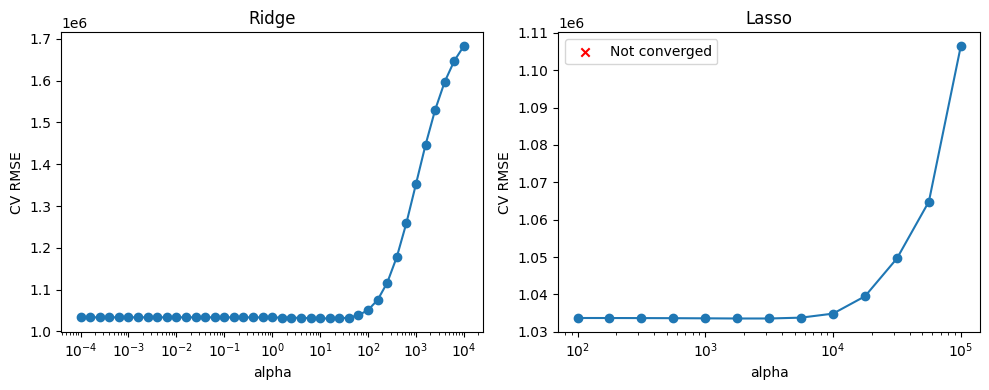

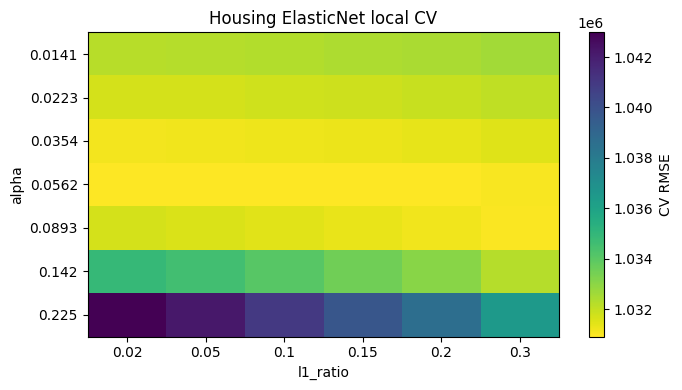

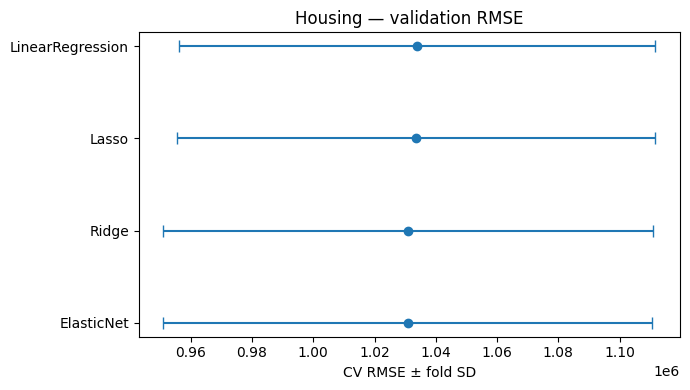

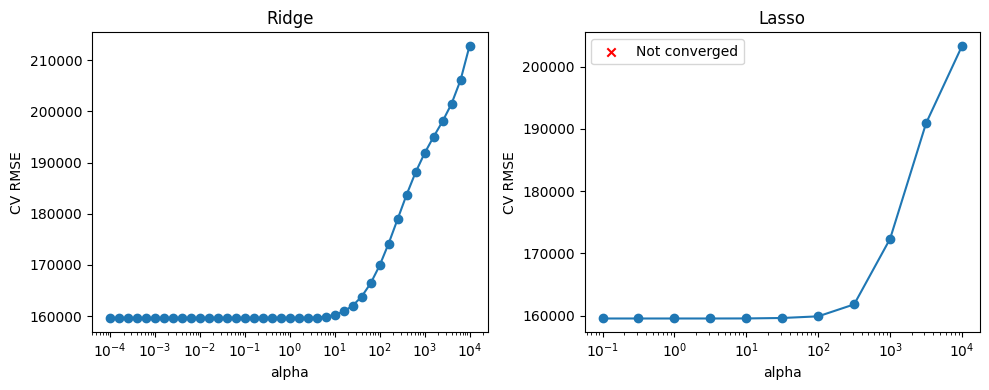

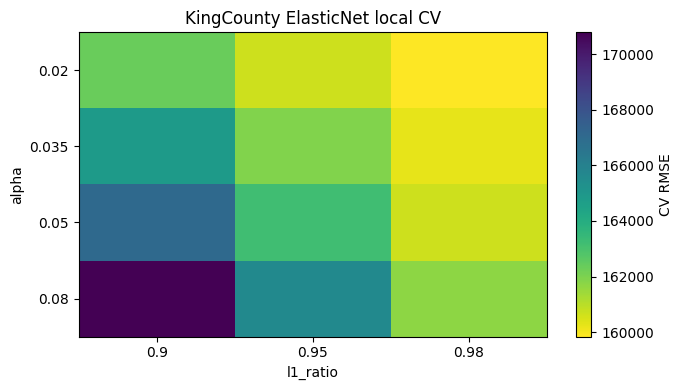

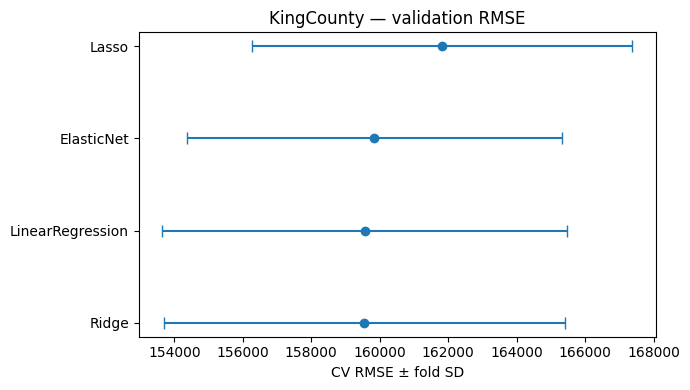

In [42]:
for ds,rr,lr,es in [('Housing',ridge_housing_result,lasso_housing_result,housing_en_refine_search),
                    ('KingCounty',ridge_kc_result,lasso_kc_result,kc_en_refine_search)]:
    for stage,search in [('coarse',rr['coarse_search']),('fine',rr['fine_search']),('elasticnet',es)]:
        pd.DataFrame(search.cv_results_).to_csv(RUN_DIR/f'{ds}_{stage}_cv_results.csv',index=False)
    lr['records'].to_csv(RUN_DIR/f'{ds}_lasso_path_folds.csv',index=False)
    lr['summary'].to_csv(RUN_DIR/f'{ds}_lasso_path_summary.csv',index=False)
    r=pd.DataFrame(rr['coarse_search'].cv_results_)
    fig,ax=plt.subplots(1,2,figsize=(10,4))
    ax[0].semilogx(r.param_model__alpha.astype(float),-r.mean_test_score,'o-')
    ax[0].set(title='Ridge',xlabel='alpha',ylabel='CV RMSE')
    l=lr['summary'];ax[1].semilogx(l.alpha,l.mean_cv_rmse,'o-')
    bad=~l.all_folds_converged
    ax[1].scatter(l.loc[bad,'alpha'],l.loc[bad,'mean_cv_rmse'],marker='x',c='red',label='Not converged')
    ax[1].set(title='Lasso',xlabel='alpha',ylabel='CV RMSE');ax[1].legend()
    savefig(ds+'_regularization_paths')
    e=pd.DataFrame(es.cv_results_);e['rmse']=-e.mean_test_score
    grid=e.pivot(index='param_model__alpha',columns='param_model__l1_ratio',values='rmse')
    fig,ax=plt.subplots(figsize=(7,4));im=ax.imshow(grid,aspect='auto',cmap='viridis_r')
    ax.set_xticks(range(len(grid.columns)),[f'{float(v):.3g}' for v in grid.columns])
    ax.set_yticks(range(len(grid.index)),[f'{float(v):.3g}' for v in grid.index])
    ax.set(xlabel='l1_ratio',ylabel='alpha',title=ds+' ElasticNet local CV')
    fig.colorbar(im,ax=ax,label='CV RMSE');savefig(ds+'_elasticnet_heatmap')
    t=cv_table[(cv_table.dataset==ds)&(cv_table.model!='DummyMean')].sort_values('cv_rmse')
    fig,ax=plt.subplots(figsize=(7,4))
    ax.errorbar(t.cv_rmse,t.model,xerr=t.cv_sd,fmt='o',capsize=4)
    ax.set(xlabel='CV RMSE ± fold SD',title=ds+' — validation RMSE')
    savefig(ds+'_cv_comparison')


## B11 · Learning curves
For the model selected on each dataset, plot RMSE against the number of training examples per fold while holding its hyperparameters fixed.


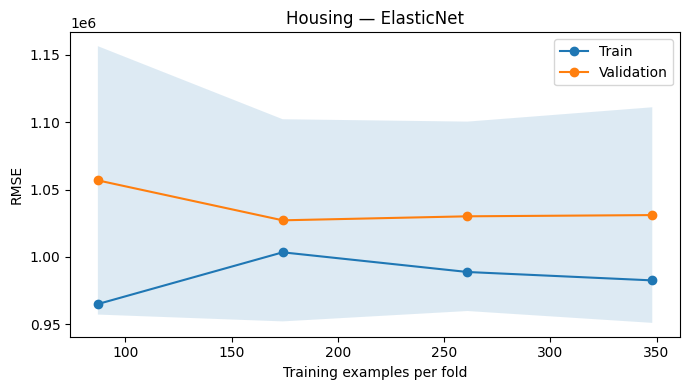

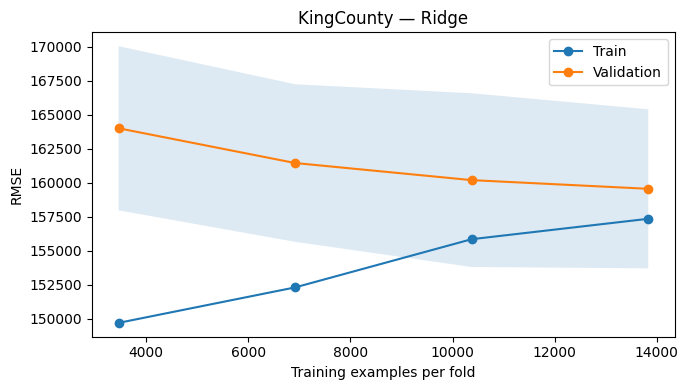

In [43]:
for _,row in selected.iterrows():
    ds,name=row['dataset'],row['model'];X,y,*_=datasets[ds]
    with warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        sizes,tr,va=learning_curve(clone(models[(ds,name)]),X,y,cv=cv,
            scoring=SCORING,train_sizes=[.25,.50,.75,1.],shuffle=True,random_state=36,
            n_jobs=1,error_score='raise')
    tr=-tr;va=-va
    pd.DataFrame({'n_train_per_fold':sizes,'train_rmse':tr.mean(1),'cv_rmse':va.mean(1),
        'cv_sd':va.std(1,ddof=1)}).to_csv(RUN_DIR/f'{ds}_learning_curve.csv',index=False)
    fig,ax=plt.subplots(figsize=(7,4));ax.plot(sizes,tr.mean(1),'o-',label='Train')
    ax.plot(sizes,va.mean(1),'o-',label='Validation')
    ax.fill_between(sizes,va.mean(1)-va.std(1,ddof=1),va.mean(1)+va.std(1,ddof=1),alpha=.15)
    ax.set(xlabel='Training examples per fold',ylabel='RMSE',title=f'{ds} — {name}');ax.legend()
    savefig(ds+'_learning_curve')


## B12 · Holdout results
Evaluate the four fitted regressors and the mean baseline on each test partition. Keep the model chosen by validation RMSE.


In [44]:
# B12 — FINAL TEST OF ALL LOCKED CONFIGURATIONS

# IMPORTANT:
# - Models were already selected/locked using training-only CV.
# - This section evaluates the already-fitted full-training models
#   on the held-out test partition.
# - Test results MUST NOT be used to revise model selection.

# 1. Pre-flight checks

required_objects = ["models", "datasets", "cv_table", "selected", "tuning_results", "RUN_DIR"]

missing_objects = [name for name in required_objects if name not in globals()]

if missing_objects:
    raise RuntimeError("B12 missing required objects: " + ", ".join(missing_objects))

assert len(models) == 10, (f"Expected 10 locked models, found {len(models)}")

assert len(X_test_h) == 109
assert len(X_test_kc) == 4323

# Confirm CV-selected winners BEFORE looking at test metrics
selected_lookup = dict(zip(selected["dataset"], selected["model"]))

print("B12 pre-flight: PASS")
print("Locked winner — Housing    :", selected_lookup["Housing"])
print("Locked winner — KingCounty :", selected_lookup["KingCounty"])

expected_selected = (cv_table[cv_table.model!='DummyMean']
    .sort_values(['dataset','cv_rmse','model'])
    .drop_duplicates('dataset').set_index('dataset')['model'].to_dict())
assert selected_lookup == expected_selected

# 2. Helper for tuning time

def get_tuning_time(dataset_name, model_name):

    if model_name in ["DummyMean", "LinearRegression"]:
        return 0.0

    tuning_dataset_name = ("King County" if dataset_name == "KingCounty" else dataset_name)

    result = tuning_results.get((tuning_dataset_name, model_name), {})

    return float(result.get("tuning_time_sec", np.nan))

# 3. Test evaluation

test_rows = []
pred_frames = []

for (dataset_name, model_name), model in models.items():

    X_train, y_train, X_test, y_test, _ = (datasets[dataset_name])

    start = time.perf_counter()

    pred = model.predict(X_test)

    predict_sec = (time.perf_counter() - start)

    actual = y_test.to_numpy()

    residual = (actual - pred)

    absolute_error = np.abs(residual)

    valid_pct_mask = (actual != 0)

    ape_pct = np.full(len(actual), np.nan, dtype=float)

    ape_pct[
        valid_pct_mask
    ] = (
        absolute_error[
            valid_pct_mask
        ]
        / np.abs(
            actual[
                valid_pct_mask
            ]
        )
        * 100
    )

    # --------------------------------------------------------
    # Model-level test metrics
    # --------------------------------------------------------

    test_rows.append({
        "dataset":
            dataset_name,

        "model":
            model_name,

        "mae":
            float(
                mean_absolute_error(
                    actual,
                    pred
                )
            ),

        "rmse":
            float(
                np.sqrt(
                    mean_squared_error(
                        actual,
                        pred
                    )
                )
            ),

        "r2":
            float(
                r2_score(
                    actual,
                    pred
                )
            ),

        "mape_pct":
            float(
                np.nanmean(
                    ape_pct
                )
            ),

        "median_ape_pct":
            float(
                np.nanmedian(
                    ape_pct
                )
            ),

        "predict_sec":
            float(
                predict_sec
            ),

        "negative_predictions":
            int(
                (pred < 0).sum()
            ),

        "test_n":
            int(
                len(actual)
            )
    })

    # --------------------------------------------------------
    # Row-level predictions
    # --------------------------------------------------------

    pred_frames.append(
        pd.DataFrame({
            "dataset":
                dataset_name,

            "model":
                model_name,

            "row_index":
                X_test.index,

            "actual":
                actual,

            "predicted":
                pred,

            "residual":
                residual,

            "absolute_error":
                absolute_error,

            "absolute_percentage_error":
                ape_pct
        })
    )

# 4. Build final tables

test_table = pd.DataFrame(test_rows)

predictions = pd.concat(pred_frames, ignore_index=True)

final_table = cv_table.merge(test_table, on=["dataset", "model"], validate="one_to_one")

final_table[
    "tuning_sec"
] = [
    get_tuning_time(
        row.dataset,
        row.model
    )
    for row
    in final_table.itertuples()
]

# 5. Validation

assert len(final_table) == 10

assert len(predictions) == (5 * 109 + 5 * 4323)

assert np.isfinite(final_table[["cv_rmse", "mae", "rmse", "r2"]].to_numpy()).all()

assert predictions["predicted"].notna().all()

assert predictions["actual"].notna().all()

# 6. Export results

final_table.to_csv(RUN_DIR / "final_results.csv", index=False)

predictions.to_csv(RUN_DIR / "test_predictions.csv", index=False)

# 7. Display

display(final_table.sort_values(["dataset", "cv_rmse"]))

print("\nB12 FINAL TEST: PASS")

print("Final result rows :", len(final_table))

print("Prediction rows   :", len(predictions))

print("\nIMPORTANT: model winners remain locked from CV.")


B12 pre-flight: PASS
Locked winner — Housing    : ElasticNet
Locked winner — KingCounty : Ridge


,dataset,model,cv_rmse,cv_sd,audit_cv_sec,fit_sec,train_rmse,mae,rmse,r2,mape_pct,median_ape_pct,predict_sec,negative_predictions,test_n,tuning_sec
3,Housing,ElasticNet,1.030916e+06,79813.079792,0.219410,0.022267,9.873740e+05,9.811970e+05,1.342667e+06,0.643342,21.428501,17.563576,0.006515,0,109,92.496080
2,Housing,Ridge,1.030919e+06,79867.297802,0.242028,0.023466,9.864978e+05,9.794402e+05,1.339700e+06,0.644916,21.365561,17.092752,0.006887,0,109,11.572884
4,Housing,Lasso,1.033564e+06,78114.858002,0.207456,0.020956,9.842851e+05,9.739934e+05,1.329345e+06,0.650384,21.149759,16.605654,0.006533,0,109,0.241614
1,Housing,LinearRegression,1.033711e+06,77680.016589,0.151043,0.015910,9.840519e+05,9.700434e+05,1.324507e+06,0.652924,21.035523,16.553242,0.007659,0,109,0.000000
0,Housing,DummyMean,1.751658e+06,162194.710270,0.148570,0.016576,1.755959e+06,1.748625e+06,2.268298e+06,-0.017926,39.892919,29.300203,0.010028,0,109,0.000000
7,KingCounty,Ridge,1.595546e+05,5853.845952,0.917375,0.180500,1.575862e+05,9.828467e+04,1.703280e+05,0.808095,19.496692,14.065503,0.013887,14,4323,63.996964
6,KingCounty,LinearRegression,1.595550e+05,5908.384758,2.274305,0.278181,1.575790e+05,9.827560e+04,1.702960e+05,0.808167,19.494402,14.060489,0.013877,13,4323,0.000000
8,KingCounty,ElasticNet,1.598413e+05,5475.540901,652.446670,163.664244,1.579380e+05,9.854149e+04,1.710816e+05,0.806393,19.559705,14.077557,0.013409,14,4323,1503.939579
9,KingCounty,Lasso,1.618239e+05,5545.011878,9.285224,2.197436,1.598933e+05,9.953988e+04,1.727541e+05,0.802589,19.664240,14.506906,0.013813,13,4323,64.705232
5,KingCounty,DummyMean,3.612867e+05,13253.983696,0.606726,0.107487,3.614535e+05,2.399988e+05,3.889875e+05,-0.000890,52.961268,37.686205,0.015377,0,4323,0.000000



B12 FINAL TEST: PASS
Final result rows : 10
Prediction rows   : 22160

IMPORTANT: model winners remain locked from CV.


## B12B · Metric verification
Recalculate the selected models' metrics from the saved predictions.


In [45]:
# B12B — Recompute metrics from predictions, without refitting
verified_rows=[]
for (ds,name),g in predictions.groupby(['dataset','model']):
    actual=g.actual.to_numpy(dtype=float); pred=g.predicted.to_numpy(dtype=float)
    assert np.isfinite(actual).all() and np.isfinite(pred).all() and (actual>0).all()
    assert not g.row_index.duplicated().any()
    np.testing.assert_allclose(actual,datasets[ds][3].loc[g.row_index].to_numpy(),rtol=0,atol=0)
    residual=actual-pred; ape=100*np.abs(residual)/actual
    np.testing.assert_allclose(g.residual,residual,rtol=1e-10,atol=1e-8)
    verified_rows.append({'dataset':ds,'model':name,'mae':float(np.abs(residual).mean()),
        'rmse':float(np.sqrt(np.mean(residual**2))),'r2':float(r2_score(actual,pred)),
        'mape_pct':float(ape.mean()),'median_ape_pct':float(np.median(ape))})
verified=pd.DataFrame(verified_rows)
comparison=final_table.merge(verified,on=['dataset','model'],suffixes=('_stored','_recomputed'),validate='one_to_one')
for metric in ['mae','rmse','r2','mape_pct','median_ape_pct']:
    np.testing.assert_allclose(comparison[metric+'_stored'],comparison[metric+'_recomputed'],rtol=1e-10,atol=1e-8,err_msg=metric)
verified_selected=verified.merge(selected[['dataset','model']],on=['dataset','model'],validate='one_to_one')
verified_selected.to_csv(RUN_DIR/'verified_selected_metrics.csv',index=False)
print(verified_selected.to_string(index=False,float_format=lambda x:f'{x:,.6f}'))


   dataset      model            mae             rmse       r2  mape_pct  median_ape_pct
   Housing ElasticNet 981,196.950020 1,342,666.900920 0.643342 21.428501       17.563576
KingCounty      Ridge  98,284.669021   170,328.037301 0.808095 19.496692       14.065503


## B13 · Residuals and errors by price range
Inspect residuals and compare errors across price bands. Define the bands using training-price quartiles, then apply those cutoffs to the test observations.


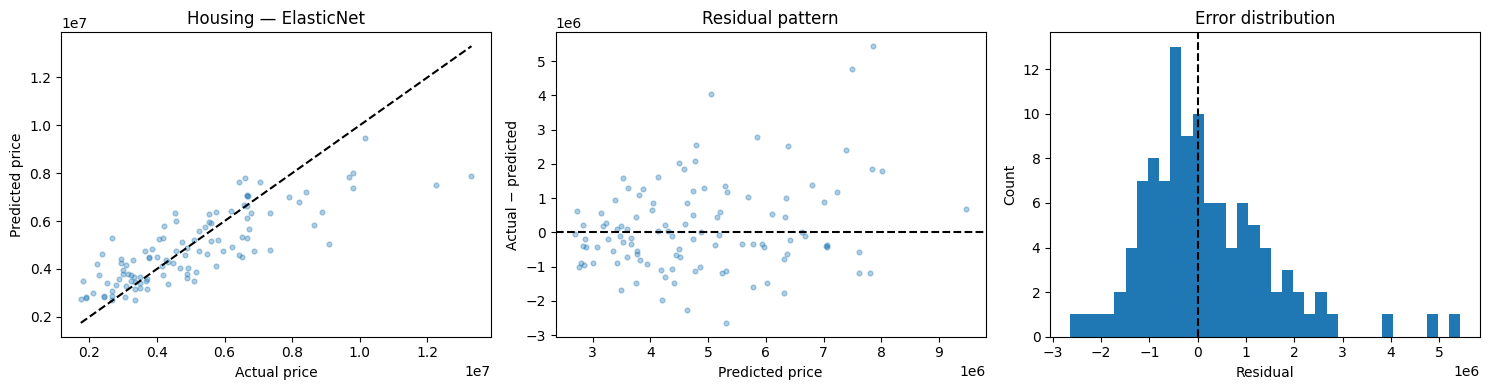

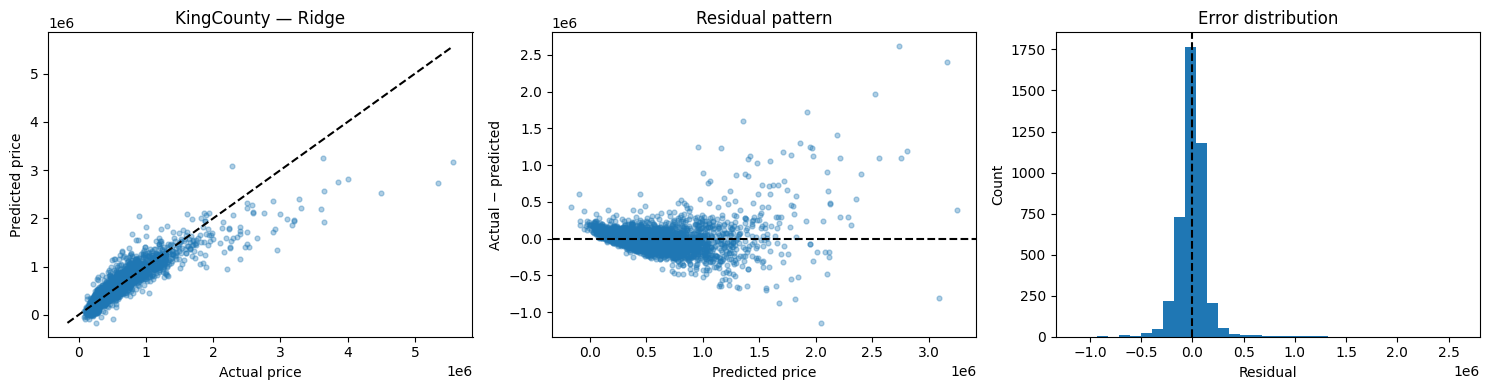

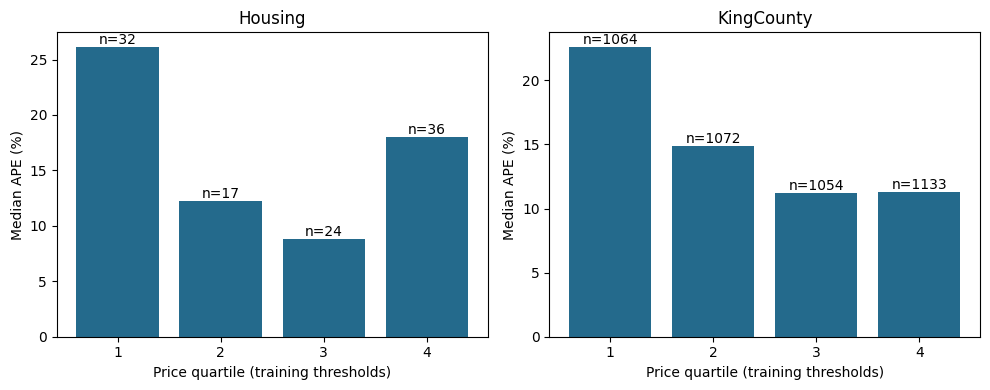

In [46]:
segment_rows=[]
for _,row in selected.iterrows():
    ds,name=row['dataset'],row['model'];X,y,Xt,yt,_=datasets[ds]
    p=predictions[(predictions.dataset==ds)&(predictions.model==name)].copy()
    fig,ax=plt.subplots(1,3,figsize=(15,4))
    ax[0].scatter(p.actual,p.predicted,s=12,alpha=.35)
    lo=min(p.actual.min(),p.predicted.min());hi=max(p.actual.max(),p.predicted.max())
    ax[0].plot([lo,hi],[lo,hi],'k--');ax[0].set(xlabel='Actual price',ylabel='Predicted price',title=ds+' — '+name)
    ax[1].scatter(p.predicted,p.residual,s=12,alpha=.35);ax[1].axhline(0,color='black',ls='--')
    ax[1].set(xlabel='Predicted price',ylabel='Actual − predicted',title='Residual pattern')
    ax[2].hist(p.residual,bins=35);ax[2].axvline(0,color='black',ls='--')
    ax[2].set(xlabel='Residual',ylabel='Count',title='Error distribution')
    savefig(ds+'_residual_diagnostics')
    bins=np.unique(np.r_[-np.inf,y.quantile([.25,.5,.75]).to_numpy(),np.inf])
    p['price_segment']=pd.cut(p.actual,bins,labels=False)
    for group,g in p.groupby('price_segment'):
        segment_rows.append({'dataset':ds,'model':name,'price_quartile':int(group)+1,'n':len(g),
          'mae':g.residual.abs().mean(),'rmse':np.sqrt(np.mean(g.residual**2)),
          'median_ape_pct':100*np.median(np.abs(g.residual/g.actual))})
    # Correlated numeric and unscaled dummy coefficients are not directly comparable importance.
    model=models[(ds,name)];prep=model.named_steps['preprocess'];base=model.named_steps['model']
    pd.DataFrame({'feature':prep.get_feature_names_out(),'coefficient':base.coef_}).to_csv(
        RUN_DIR/f'{ds}_selected_coefficients.csv',index=False)
segments=pd.DataFrame(segment_rows);segments.to_csv(RUN_DIR/'price_segment_errors.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,ds in zip(axes,datasets):
    s=segments[segments.dataset==ds]
    ax.bar(s.price_quartile,s.median_ape_pct,color='#246a8c')
    ax.set(xticks=[1,2,3,4],xlabel='Price quartile (training thresholds)',ylabel='Median APE (%)',title=ds)
    for _,r in s.iterrows():ax.text(r.price_quartile,r.median_ape_pct,f"n={int(r['n'])}",ha='center',va='bottom')
savefig('price_segment_errors')


In [47]:
# B13B — FINAL ERROR ANALYSIS + WORST CASES

# Adds:
# - selected-model predictions only
# - complete price-segment metrics
# - top-20 worst prediction cases
# - negative-prediction audit
#
# No tuning or model selection occurs here.

# 1. Selected-model predictions only

selected_keys = selected[["dataset", "model"]].copy()

selected_predictions = predictions.merge(
    selected_keys,
    on=["dataset", "model"],
    how="inner",
    validate="many_to_one"
)

assert len(selected_predictions) == (len(X_test_h) + len(X_test_kc))

assert len(selected_predictions) == 4432

assert selected_predictions["actual"].notna().all()

assert selected_predictions["predicted"].notna().all()

print("Selected-model prediction rows:", len(selected_predictions))

# 2. Prediction direction
# residual = actual - predicted
#
# residual > 0 -> underprediction
# residual < 0 -> overprediction

selected_predictions[
    "prediction_direction"
] = np.select(
    [
        selected_predictions["residual"] > 0,
        selected_predictions["residual"] < 0
    ],
    [
        "underprediction",
        "overprediction"
    ],
    default="exact"
)

# 3. Price-segment analysis
#
# IMPORTANT:
# Quartile thresholds are calculated from TRAINING target only.
# They are then applied to test observations.

segment_records = []
segment_frames = []

segment_labels = ["Q1_Low", "Q2_MidLow", "Q3_MidHigh", "Q4_High"]

for _, selected_row in selected.iterrows():

    dataset_name = selected_row["dataset"]

    model_name = selected_row["model"]

    (X_train, y_train, X_test, y_test, _) = datasets[dataset_name]

    p = selected_predictions[
        (
            selected_predictions["dataset"]
            == dataset_name
        )
        &
        (
            selected_predictions["model"]
            == model_name
        )
    ].copy()

    # Training-only quartile thresholds
    q1, q2, q3 = (y_train .quantile([0.25, 0.50, 0.75]) .to_numpy())

    bins = [-np.inf, q1, q2, q3, np.inf]

    p["price_segment"] = pd.cut(p["actual"], bins=bins, labels=segment_labels, include_lowest=True)

    segment_frames.append(p)

    for segment_name, group in p.groupby("price_segment", observed=False):

        if len(group) == 0:
            continue

        segment_records.append({
            "dataset":
                dataset_name,

            "model":
                model_name,

            "price_segment":
                str(segment_name),

            "n":
                int(
                    len(group)
                ),

            "mae":
                float(
                    group[
                        "absolute_error"
                    ].mean()
                ),

            "rmse":
                float(
                    np.sqrt(
                        np.mean(
                            group[
                                "residual"
                            ] ** 2
                        )
                    )
                ),

            "mape_pct":
                float(
                    group[
                        "absolute_percentage_error"
                    ].mean()
                ),

            "median_ape_pct":
                float(
                    group[
                        "absolute_percentage_error"
                    ].median()
                ),

            "mean_residual":
                float(
                    group[
                        "residual"
                    ].mean()
                ),

            "underprediction_rate_pct":
                float(
                    100
                    * (
                        group[
                            "residual"
                        ] > 0
                    ).mean()
                ),

            "train_q1":
                float(q1),

            "train_median":
                float(q2),

            "train_q3":
                float(q3)
        })

price_segment_errors = pd.DataFrame(segment_records)

selected_predictions_segmented = pd.concat(segment_frames, ignore_index=True)

# 4. Validate price-segment accounting

segment_counts = (price_segment_errors .groupby("dataset")["n"] .sum())

assert (segment_counts["Housing"] == 109)

assert (segment_counts["KingCounty"] == 4323)

assert len(price_segment_errors) == 8

print("\nPrice-segment analysis: PASS")

display(
    price_segment_errors[
        [
            "dataset",
            "model",
            "price_segment",
            "n",
            "mae",
            "rmse",
            "mape_pct",
            "median_ape_pct",
            "mean_residual",
            "underprediction_rate_pct"
        ]
    ]
)

# 5. Top-20 worst prediction errors per selected model

error_cases = (
    selected_predictions_segmented
    .sort_values(
        [
            "dataset",
            "absolute_error"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "dataset",
        group_keys=False
    )
    .head(20)
    .copy()
)

error_cases["error_rank"] = (error_cases .groupby("dataset") .cumcount() + 1)

error_cases = error_cases[
    [
        "dataset",
        "model",
        "error_rank",
        "row_index",
        "price_segment",
        "actual",
        "predicted",
        "residual",
        "absolute_error",
        "absolute_percentage_error",
        "prediction_direction"
    ]
]

assert len(error_cases[error_cases["dataset"] == "Housing"]) == 20

assert len(error_cases[error_cases["dataset"] == "KingCounty"]) == 20

print("\nTop error cases: PASS")

display(error_cases.head(10))

# 6. Negative-prediction audit

negative_prediction_audit = (
    selected_predictions[
        selected_predictions[
            "predicted"
        ] < 0
    ]
    .groupby(
        [
            "dataset",
            "model"
        ]
    )
    .size()
    .reset_index(
        name="negative_predictions"
    )
)

print("\nNegative prediction audit")

if len(negative_prediction_audit) == 0:

    print("No negative predictions.")

else:

    display(negative_prediction_audit)

# 7. Export error-analysis outputs

price_segment_errors.to_csv(RUN_DIR / "price_segment_errors.csv", index=False)

error_cases.to_csv(RUN_DIR / "error_cases.csv", index=False)

selected_predictions_segmented.to_csv(RUN_DIR / "selected_model_predictions.csv", index=False)

negative_prediction_audit.to_csv(RUN_DIR / "negative_prediction_audit.csv", index=False)

# 8. Final B13B QA

assert (RUN_DIR / "price_segment_errors.csv").exists()

assert (RUN_DIR / "error_cases.csv").exists()

assert (RUN_DIR / "selected_model_predictions.csv").exists()

print("\nB13B FINAL ERROR ANALYSIS: PASS")

print("Selected predictions:", len(selected_predictions_segmented))

print("Price segment rows :", len(price_segment_errors))

print("Worst-error rows   :", len(error_cases))


Selected-model prediction rows: 4432

Price-segment analysis: PASS


,dataset,model,price_segment,n,mae,rmse,mape_pct,median_ape_pct,mean_residual,underprediction_rate_pct
0,Housing,ElasticNet,Q1_Low,32,8.518109e+05,1.059009e+06,34.202293,26.146018,-7.871790e+05,9.375000
1,Housing,ElasticNet,Q2_MidLow,17,5.797641e+05,7.412556e+05,14.795170,12.219591,-3.813869e+05,41.176471
2,Housing,ElasticNet,Q3_MidHigh,24,6.737065e+05,8.427213e+05,13.671252,8.847140,1.637307e+05,58.333333
3,Housing,ElasticNet,Q4_High,36,1.490766e+06,1.930940e+06,18.377924,18.005265,1.209627e+06,75.000000
4,KingCounty,Ridge,Q1_Low,1064,6.906050e+04,8.978324e+04,28.817340,22.619668,2.006411e+04,64.097744
5,KingCounty,Ridge,Q2_MidLow,1072,7.188902e+04,9.459535e+04,18.885538,14.913130,-1.862258e+04,43.283582
6,KingCounty,Ridge,Q3_MidHigh,1054,8.514055e+04,1.208364e+05,15.911338,11.228034,-2.981481e+04,43.548387
7,KingCounty,Ridge,Q4_High,1133,1.629312e+05,2.847366e+05,14.657287,11.276754,3.610568e+04,51.721094



Top error cases: PASS


,dataset,model,error_rank,row_index,price_segment,actual,predicted,residual,absolute_error,absolute_percentage_error,prediction_direction
88,Housing,ElasticNet,1,0,Q4_High,13300000.0,7.860862e+06,5.439138e+06,5.439138e+06,40.895774,underprediction
25,Housing,ElasticNet,2,2,Q4_High,12250000.0,7.489405e+06,4.760595e+06,4.760595e+06,38.861998,underprediction
104,Housing,ElasticNet,3,15,Q4_High,9100000.0,5.054404e+06,4.045596e+06,4.045596e+06,44.457099,underprediction
91,Housing,ElasticNet,4,22,Q4_High,8645000.0,5.849100e+06,2.795900e+06,2.795900e+06,32.341235,underprediction
15,Housing,ElasticNet,5,499,Q1_Low,2660000.0,5.304819e+06,-2.644819e+06,2.644819e+06,99.429287,overprediction
17,Housing,ElasticNet,6,55,Q4_High,7350000.0,4.786444e+06,2.563556e+06,2.563556e+06,34.878314,underprediction
101,Housing,ElasticNet,7,18,Q4_High,8890000.0,6.378700e+06,2.511300e+06,2.511300e+06,28.248591,underprediction
56,Housing,ElasticNet,8,9,Q4_High,9800000.0,7.390460e+06,2.409540e+06,2.409540e+06,24.587145,underprediction
39,Housing,ElasticNet,9,523,Q1_Low,2380000.0,4.637644e+06,-2.257644e+06,2.257644e+06,94.858993,overprediction
78,Housing,ElasticNet,10,68,Q4_High,6860000.0,4.766775e+06,2.093225e+06,2.093225e+06,30.513484,underprediction



Negative prediction audit


,dataset,model,negative_predictions
0,KingCounty,Ridge,14



B13B FINAL ERROR ANALYSIS: PASS
Selected predictions: 4432
Price segment rows : 8
Worst-error rows   : 40


## B13C · Price-band totals and individual cases
Check group counts and export example predictions for the report.


In [48]:
# B13C — Validate segment totals and export exact report examples
for (ds,name),g in price_segment_errors.groupby(['dataset','model']):
    expected=verified[(verified.dataset==ds)&(verified.model==name)].iloc[0]
    np.testing.assert_allclose(np.average(g.mae,weights=g.n),expected.mae,rtol=1e-10,atol=1e-8)
    np.testing.assert_allclose(np.sqrt(np.average(g.rmse**2,weights=g.n)),expected.rmse,rtol=1e-10,atol=1e-8)
report_cases=selected_predictions_segmented[
    (selected_predictions_segmented.dataset=='Housing') &
    selected_predictions_segmented.row_index.isin([0,499])].copy()
report_cases.to_csv(RUN_DIR/'report_housing_cases.csv',index=False)
display(report_cases)


,dataset,model,row_index,actual,predicted,residual,absolute_error,absolute_percentage_error,prediction_direction,price_segment
15,Housing,ElasticNet,499,2660000.0,5.304819e+06,-2.644819e+06,2.644819e+06,99.429287,overprediction,Q1_Low
88,Housing,ElasticNet,0,13300000.0,7.860862e+06,5.439138e+06,5.439138e+06,40.895774,underprediction,Q4_High


## B13D · Lasso coefficient paths
Track how the Housing coefficients change as the penalty increases.


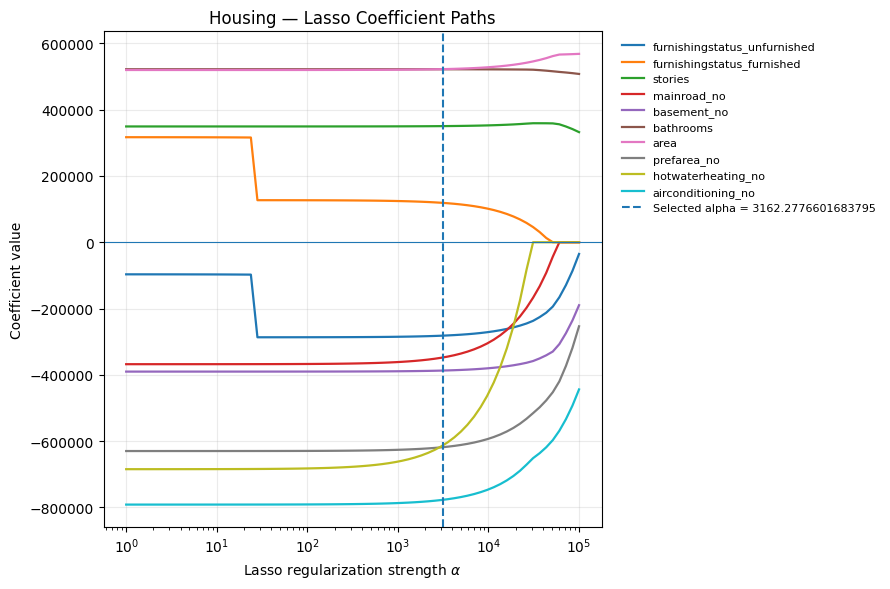

In [49]:
# HOUSING LASSO COEFFICIENT PATH
# Post-hoc diagnostic figure only

# Fit preprocessing on the full TRAINING partition only.
# This figure is for interpretation, not model selection.

path_preprocessor = clone(housing_preprocessor)

X_path = path_preprocessor.fit_transform(X_train_h, y_train_h)

feature_names = (path_preprocessor .get_feature_names_out())

# Cover weak -> strong regularization.
# This range contains both:
# CV-min alpha = 3162.28
# 1-SE alpha   = 56234.13
path_alphas = np.logspace(0, 5, 70)

coef_path = []

for alpha in path_alphas:

    model = Lasso(alpha=alpha, max_iter=100000, tol=1e-4, selection="cyclic")

    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        model.fit(X_path, y_train_h)

    coef_path.append(model.coef_.copy())

coef_path = np.asarray(coef_path)

# Select the 10 most influential transformed features
# across the full path to keep the figure readable.

max_abs_coef = np.max(np.abs(coef_path), axis=0)

top_n = 10

top_idx = np.argsort(max_abs_coef)[-top_n:]

# Plot

fig, ax = plt.subplots(figsize=(9, 6))

for idx in top_idx:

    label = (feature_names[idx] .replace("num__", "") .replace("cat__", ""))

    ax.plot(path_alphas, coef_path[:, idx], linewidth=1.6, label=label)

# Final selected Housing Lasso alpha
ax.axvline(
    configurations["Housing/Lasso"]["alpha"],
    linestyle="--",
    linewidth=1.5,
    label="Selected alpha = " + str(configurations["Housing/Lasso"]["alpha"])
)

ax.axhline(0, linewidth=0.8)

ax.set_xscale("log")

ax.set_xlabel(r"Lasso regularization strength $\alpha$")

ax.set_ylabel("Coefficient value")

ax.set_title("Housing — Lasso Coefficient Paths")

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, frameon=False)

ax.grid(alpha=0.25)

plt.tight_layout()

# Save the coefficient path figure.
savefig("Housing_lasso_coefficient_path")


## B14 · Export results
Save the search tables, selected configurations, predictions and figures. Download the final archive and the executed notebook before ending the Colab session.


In [50]:
pd.DataFrame(housing_en_search.cv_results_).to_csv(RUN_DIR/'Housing_elasticnet_coarse.csv',index=False)
pd.DataFrame(kc_en_screen_search.cv_results_).to_csv(RUN_DIR/'KingCounty_elasticnet_screen.csv',index=False)
notes={
 'selection':'training-only CV; test not used to revise configs',
 'caveat':'An earlier experiment evaluated selected models on this holdout.',
 'split':split_provenance,
 'uncertainty':'fold SD is descriptive; selected CV is not nested CV',
 'scope':'4 linear-family models + DummyMean; no SVR in this delivery',
 'boundary':'ElasticNet KingCounty local search can be boundary-limited',
 'units':'report raw dataset price units; do not assume common currency',
 'runtime':'fit_sec excludes search; do not compare it against DL training+tuning time'}
(RUN_DIR/'protocol_notes.json').write_text(json.dumps(notes,indent=2))
assert (RUN_DIR/'final_results.csv').exists() and len(list(FIG_DIR.glob('*.png')))>=10
archive=shutil.make_archive(str(RESULTS_DIR/'Nam_Reviewed_Results'),'zip',root_dir=RUN_DIR)
print('COMPLETE:',archive)
print('Also download the executed notebook from Colab.')


COMPLETE: /content/P4DS_Housing_Nam/results/Nam_Reviewed_Results.zip
Also download the executed notebook from Colab.


In [51]:
# B14B — FINAL TEAM HANDOFF EXPORTS + FINAL QA

import json
import shutil

# 1. FINAL PRE-FLIGHT

required_objects = [
    "cv_table",
    "final_table",
    "predictions",
    "selected",
    "selected_predictions_segmented",
    "price_segment_errors",
    "error_cases",
    "negative_prediction_audit",
    "configurations",
    "RUN_DIR"
]

missing_objects = [name for name in required_objects if name not in globals()]

if missing_objects:
    raise RuntimeError("B14B missing required objects: " + ", ".join(missing_objects))

print("B14B pre-flight: PASS")

# 2. COMMON MODEL SCOPE

NAM_MODELS = ["LinearRegression", "Ridge", "Lasso", "ElasticNet"]

selected_lookup = dict(zip(selected["dataset"], selected["model"]))

expected_selected = (cv_table[cv_table.model!='DummyMean']
    .sort_values(['dataset','cv_rmse','model'])
    .drop_duplicates('dataset').set_index('dataset')['model'].to_dict())
assert selected_lookup == expected_selected

# 3. NAM CV RESULTS

nam_cv_results = (cv_table[cv_table["model"].isin(NAM_MODELS)] .copy())

nam_cv_results[
    "selected_by_cv"
] = [
    (
        selected_lookup[
            row.dataset
        ]
        == row.model
    )
    for row
    in nam_cv_results.itertuples()
]

# Add final hyperparameters

def get_config_value(dataset_name, model_name, param_name):

    config = configurations.get(f"{dataset_name}/{model_name}", {})

    return config.get(param_name, np.nan)

nam_cv_results[
    "final_alpha"
] = [
    get_config_value(
        row.dataset,
        row.model,
        "alpha"
    )
    if row.model in [
        "Ridge",
        "Lasso",
        "ElasticNet"
    ]
    else np.nan

    for row
    in nam_cv_results.itertuples()
]

nam_cv_results[
    "final_l1_ratio"
] = [
    get_config_value(
        row.dataset,
        row.model,
        "l1_ratio"
    )
    if row.model == "ElasticNet"
    else np.nan

    for row
    in nam_cv_results.itertuples()
]

# Search method documentation

def search_method(dataset_name, model_name):

    if model_name == "LinearRegression":

        return ("No hyperparameter tuning")

    if model_name == "Ridge":

        return ("Coarse-to-fine GridSearchCV")

    if model_name == "Lasso":
        return "Fold-safe warm-start path CV; " + configurations[f"{dataset_name}/Lasso"]["selection_rule"]

    if model_name == "ElasticNet":

        if dataset_name == "Housing":

            return ("GridSearchCV + " "local refinement")

        return ("RandomizedSearchCV screening " "+ local refinement")

    return "N/A"

nam_cv_results[
    "search_method"
] = [
    search_method(
        row.dataset,
        row.model
    )

    for row
    in nam_cv_results.itertuples()
]

# Tuning time

nam_cv_results[
    "tuning_sec"
] = [
    get_tuning_time(
        row.dataset,
        row.model
    )

    for row
    in nam_cv_results.itertuples()
]

nam_cv_results["cv_folds"] = 5

nam_cv_results["cv_seed"] = 36

nam_cv_results["fold_safe_preprocessing"] = True

nam_cv_results["status"] = "final_audited"

# 4. NAM TEST RESULTS

nam_test_results = (final_table[final_table["model"].isin(NAM_MODELS)] .copy())

nam_test_results[
    "selected_by_cv"
] = [
    (
        selected_lookup[
            row.dataset
        ]
        == row.model
    )

    for row
    in nam_test_results.itertuples()
]

# 5. BASELINE RESULTS

nam_baseline_results = (
    final_table[
        final_table[
            "model"
        ].isin(
            [
                "DummyMean",
                "LinearRegression"
            ]
        )
    ]
    .copy()
)

# 6. FINAL SELECTED-MODEL PREDICTIONS

nam_predictions = (selected_predictions_segmented .copy())

nam_predictions = (
    nam_predictions.rename(
        columns={
            "actual":
                "actual_price",

            "predicted":
                "predicted_price"
        }
    )
)

# 7. BEST PARAMS JSON

def to_builtin(value):

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        return float(value)

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, dict):
        return { key: to_builtin(val) for key, val in value.items() }

    if isinstance(value, (list, tuple)):
        return [to_builtin(v) for v in value]

    return value

best_params_output = {
    "protocol": {
        "train_test_split":
            "fixed 80/20 split",

        "split_random_state":
            42 if split_provenance["mode"] == "reconstructed_seed42" else None,
        "split_provenance": split_provenance,

        "cv_folds":
            5,

        "cv_seed":
            36,

        "primary_selection_metric":
            "RMSE",

        "test_used_for_model_selection":
            False,
        "historical_test_exposure": True
    },

    "Housing": {
        "selected_model":
            selected_lookup["Housing"],

        "models": {}
    },

    "KingCounty": {
        "selected_model":
            selected_lookup["KingCounty"],

        "models": {}
    }
}

for dataset_name in ["Housing", "KingCounty"]:

    dataset_cv = nam_cv_results[nam_cv_results["dataset"] == dataset_name]

    for _, row in dataset_cv.iterrows():

        model_name = row["model"]

        config = configurations.get(f"{dataset_name}/{model_name}", {})

        model_entry = {
            "cv_rmse":
                float(
                    row[
                        "cv_rmse"
                    ]
                ),

            "cv_sd":
                float(
                    row[
                        "cv_sd"
                    ]
                ),

            "selected_by_cv":
                bool(
                    row[
                        "selected_by_cv"
                    ]
                ),

            "search_method":
                row[
                    "search_method"
                ],

            "parameters":
                to_builtin(
                    config
                )
        }

        best_params_output[dataset_name]["models"][model_name] = model_entry

# Explicit methodological notes

best_params_output['KingCounty']['lasso_audit'] = {
    'selection_rule': configurations['KingCounty/Lasso']['selection_rule'],
    'fallback_attempts': configurations['KingCounty/Lasso']['fallback_attempts']}

best_params_output[
    "KingCounty"
][
    "elasticnet_note"
] = (
    "The practical ElasticNet result is "
    "boundary-limited and is not claimed "
    "to be a global mathematical optimum."
)

# 8. EXPORT STANDARDIZED FILES

nam_cv_results.to_csv(RUN_DIR / "nam_cv_results.csv", index=False)

nam_baseline_results.to_csv(RUN_DIR / "nam_baseline_results.csv", index=False)

nam_test_results.to_csv(RUN_DIR / "nam_test_results.csv", index=False)

nam_predictions.to_csv(RUN_DIR / "nam_predictions.csv", index=False)

price_segment_errors.to_csv(RUN_DIR / "price_segment_errors.csv", index=False)

error_cases.to_csv(RUN_DIR / "error_cases.csv", index=False)

negative_prediction_audit.to_csv(RUN_DIR / "negative_prediction_audit.csv", index=False)

with open(RUN_DIR / "nam_best_params.json", "w", encoding="utf-8") as f:

    json.dump(best_params_output, f, indent=2, ensure_ascii=False)

# 9. FINAL MODEL SUMMARY

selected_test_results = (nam_test_results[nam_test_results["selected_by_cv"]] .copy())

selected_test_results.to_csv(RUN_DIR / "nam_selected_model_results.csv", index=False)

print("\nFINAL SELECTED MODELS")

display(
    selected_test_results[
        [
            "dataset",
            "model",
            "cv_rmse",
            "mae",
            "rmse",
            "r2",
            "mape_pct",
            "median_ape_pct",
            "fit_sec",
            "predict_sec"
        ]
    ]
)

# 10. FINAL QA

# Target leakage
assert ("price" not in X_train_h.columns)

assert ("price" not in X_test_h.columns)

assert ("price" not in X_train_kc.columns)

assert ("price" not in X_test_kc.columns)

# Fixed split sizes
assert len(X_train_h) == 436
assert len(X_test_h) == 109

assert len(X_train_kc) == 17290
assert len(X_test_kc) == 4323

# Expected CV/test records
assert len(nam_cv_results) == 8

assert len(nam_test_results) == 8

# Selected predictions
assert len(nam_predictions) == 4432

assert nam_predictions["predicted_price"].notna().all()

assert nam_predictions["actual_price"].notna().all()

# Error analysis
assert len(error_cases) == 40

assert len(price_segment_errors) == 8

# Required files
required_output_files = [
    "nam_baseline_results.csv",
    "nam_cv_results.csv",
    "nam_best_params.json",
    "nam_test_results.csv",
    "nam_predictions.csv",
    "nam_selected_model_results.csv",
    "error_cases.csv",
    "price_segment_errors.csv",
    "negative_prediction_audit.csv"
]

missing_files = [
    filename

    for filename
    in required_output_files

    if not (
        RUN_DIR
        / filename
    ).exists()
]

assert not missing_files, ("Missing output files: " + str(missing_files))

# 11. PACKAGE FINAL HANDOFF

archive_path = shutil.make_archive(
    str(
        RESULTS_DIR
        / "Nam_FINAL_Results_v2"
    ),
    "zip",
    root_dir=RUN_DIR
)

# 12. FINAL STATUS

print("\n========================================")

print("Export checks passed")

print("========================================")

print("CV rows            :", len(nam_cv_results))

print("Test rows          :", len(nam_test_results))

print("Final predictions  :", len(nam_predictions))

print("Error cases        :", len(error_cases))

print("Price segment rows :", len(price_segment_errors))

print("\nHousing winner     :", selected_lookup["Housing"])

print("KingCounty winner  :", selected_lookup["KingCounty"])

print("\nFinal archive:")

print(archive_path)


B14B pre-flight: PASS

FINAL SELECTED MODELS


,dataset,model,cv_rmse,mae,rmse,r2,mape_pct,median_ape_pct,fit_sec,predict_sec
3,Housing,ElasticNet,1.030916e+06,981196.950020,1.342667e+06,0.643342,21.428501,17.563576,0.022267,0.006515
7,KingCounty,Ridge,1.595546e+05,98284.669021,1.703280e+05,0.808095,19.496692,14.065503,0.180500,0.013887



Export checks passed
CV rows            : 8
Test rows          : 8
Final predictions  : 4432
Error cases        : 40
Price segment rows : 8

Housing winner     : ElasticNet
KingCounty winner  : Ridge

Final archive:
/content/P4DS_Housing_Nam/results/Nam_FINAL_Results_v2.zip


## Report notes
Use scores, timings and settings from the same run. Check `ridge_recheck.csv` for fold discrepancies. The King County split is transaction-level, and earlier experiments used these holdout data.
